In [1]:
# Run All starts 2 pilot + 12 formal models, serially. No historical weights loaded.
EXISTING_DATA_RUN = '20261019T090430_205588Z_Top10_LSTM_F2'  # acceptance may reuse THIS TASK's already qualified P0/P1

from pathlib import Path
import sys
if '__file__' in globals():FOLDER=Path(__file__).resolve().parent
else:
    options=[Path.cwd(),Path.cwd()/'F2_LSTM_DualPath_Comparison',Path.cwd()/'RENew-PEMFC-2300h-Pytorch/F2_LSTM_DualPath_Comparison']
    FOLDER=next(p for p in options if (p/'core.py').exists() and (p/'Comparison_Interactive.py').exists())
if str(FOLDER) not in sys.path:sys.path.insert(0,str(FOLDER))
import core as c
from stages import prepare_run,diagnose_existing
from training import pilot,formal_train,formal_evaluate
from io_utils import js
from IPython.display import display,Markdown

In [2]:
if EXISTING_DATA_RUN is None:
    run,frame,windows,scaler,prepared,protocol=prepare_run()
    diagnosis=diagnose_existing(run,frame,windows,protocol)
else:
    run=FOLDER/'outputs'/EXISTING_DATA_RUN
    c.require(not (run/'INVALIDATED_BEFORE_TRAINING.json').exists(),'INVALIDATED_DATA_RUN')
    c.require(c.read_json(run/'P0_ACCEPTANCE.json')['status']=='PASS' and c.read_json(run/'P1_ACCEPTANCE.json')['status']=='PASS','P0_P1_NOT_PASSED')
    c.require(not (run/'models').exists(),'REFUSE_REPEAT_OR_OVERWRITE_TRAINING')
    frame,windows,scaler,prepared,excluded=c.load_data();protocol=c.read_json(run/'FROZEN_PROTOCOL.json')
    c.require(c.sha(c.SOURCE)==protocol['data_sha256'] and c.sha(FOLDER/'core.py')==protocol['core_sha256'],'PREQUALIFIED_DATA_SOURCE_CHANGED')
    c.configure_environment()
display(Markdown('**P0/P1 passed.** Fixed Top10, 1750 Train /218 Validation /527 exploratory holdout origins. No strict CUDA mode.'))
display(c.read_csv(run/'PARTITIONS.csv'))

**P0/P1 passed.** Fixed Top10, 1750 Train /218 Validation /527 exploratory holdout origins. No strict CUDA mode.

,partition,start_row,end_row_exclusive,records,first_operating_h,last_operating_h,first_datetime,last_datetime,legal_origins,queries,unique_targets,origin_sha256,target_sha256,labels_sha256,inputs_sha256,maximum_adjacent_calendar_gap_s
0,TRAIN,0,2690,2690,73.0,1622,2025-01-27 12:09:18.005000,2025-06-05 13:55:02.005000,1750,42000,2026,ad15fed16bcc2ec273081ef937cfe916282df8f6274ba2...,ebdc9770a9cc455465ee7e4558987b9ccb187f51a32e96...,5e7d7f27b1e6fe9662c1664f1ccc526fdb3f479c65dc6a...,a0e74eb627c8691b3fdd7d863d0b87b2f10657d59b75a8...,1.001
1,VALIDATION,2690,3074,384,1622.5,1854,2025-06-05 13:55:03.005000,2025-07-01 07:30:15.005000,218,5232,264,eff6c1a900cde755f33dbde0e20e7b30bd8b1a670cf3c3...,5572ab2b1d6f8046e035fe480d7340f603aad37a424ad2...,755d829508334add56b1c09a2bba887cda3c436dede09f...,21b94472296e4b36095dc9cac983f1bd9ba1a7b657ab0b...,1.001
2,TEST,3074,3843,769,1854.5,2257,2025-07-01 07:30:16.005000,2025-07-26 12:06:23.005000,527,12648,619,4a37f72bc864d1166b7245ac119b92331ba38eab158489...,89e171b7b92c0eeb396982bafda914ea450aa01509abd4...,d4015947028d3f980c256f2c4c30a770725acab6407d12...,4c408ac792825c01d78ef03ef894f5ae948066b6103364...,1.001


Training pilot LSTM Seed 202: 22040 parameters, fresh weights/AdamW
pilot LSTM Seed 202 | Epoch 1/450 | Train Loss 1.790430 | Validation Loss 1.284865 | Best Epoch 1 | Patience 0/40


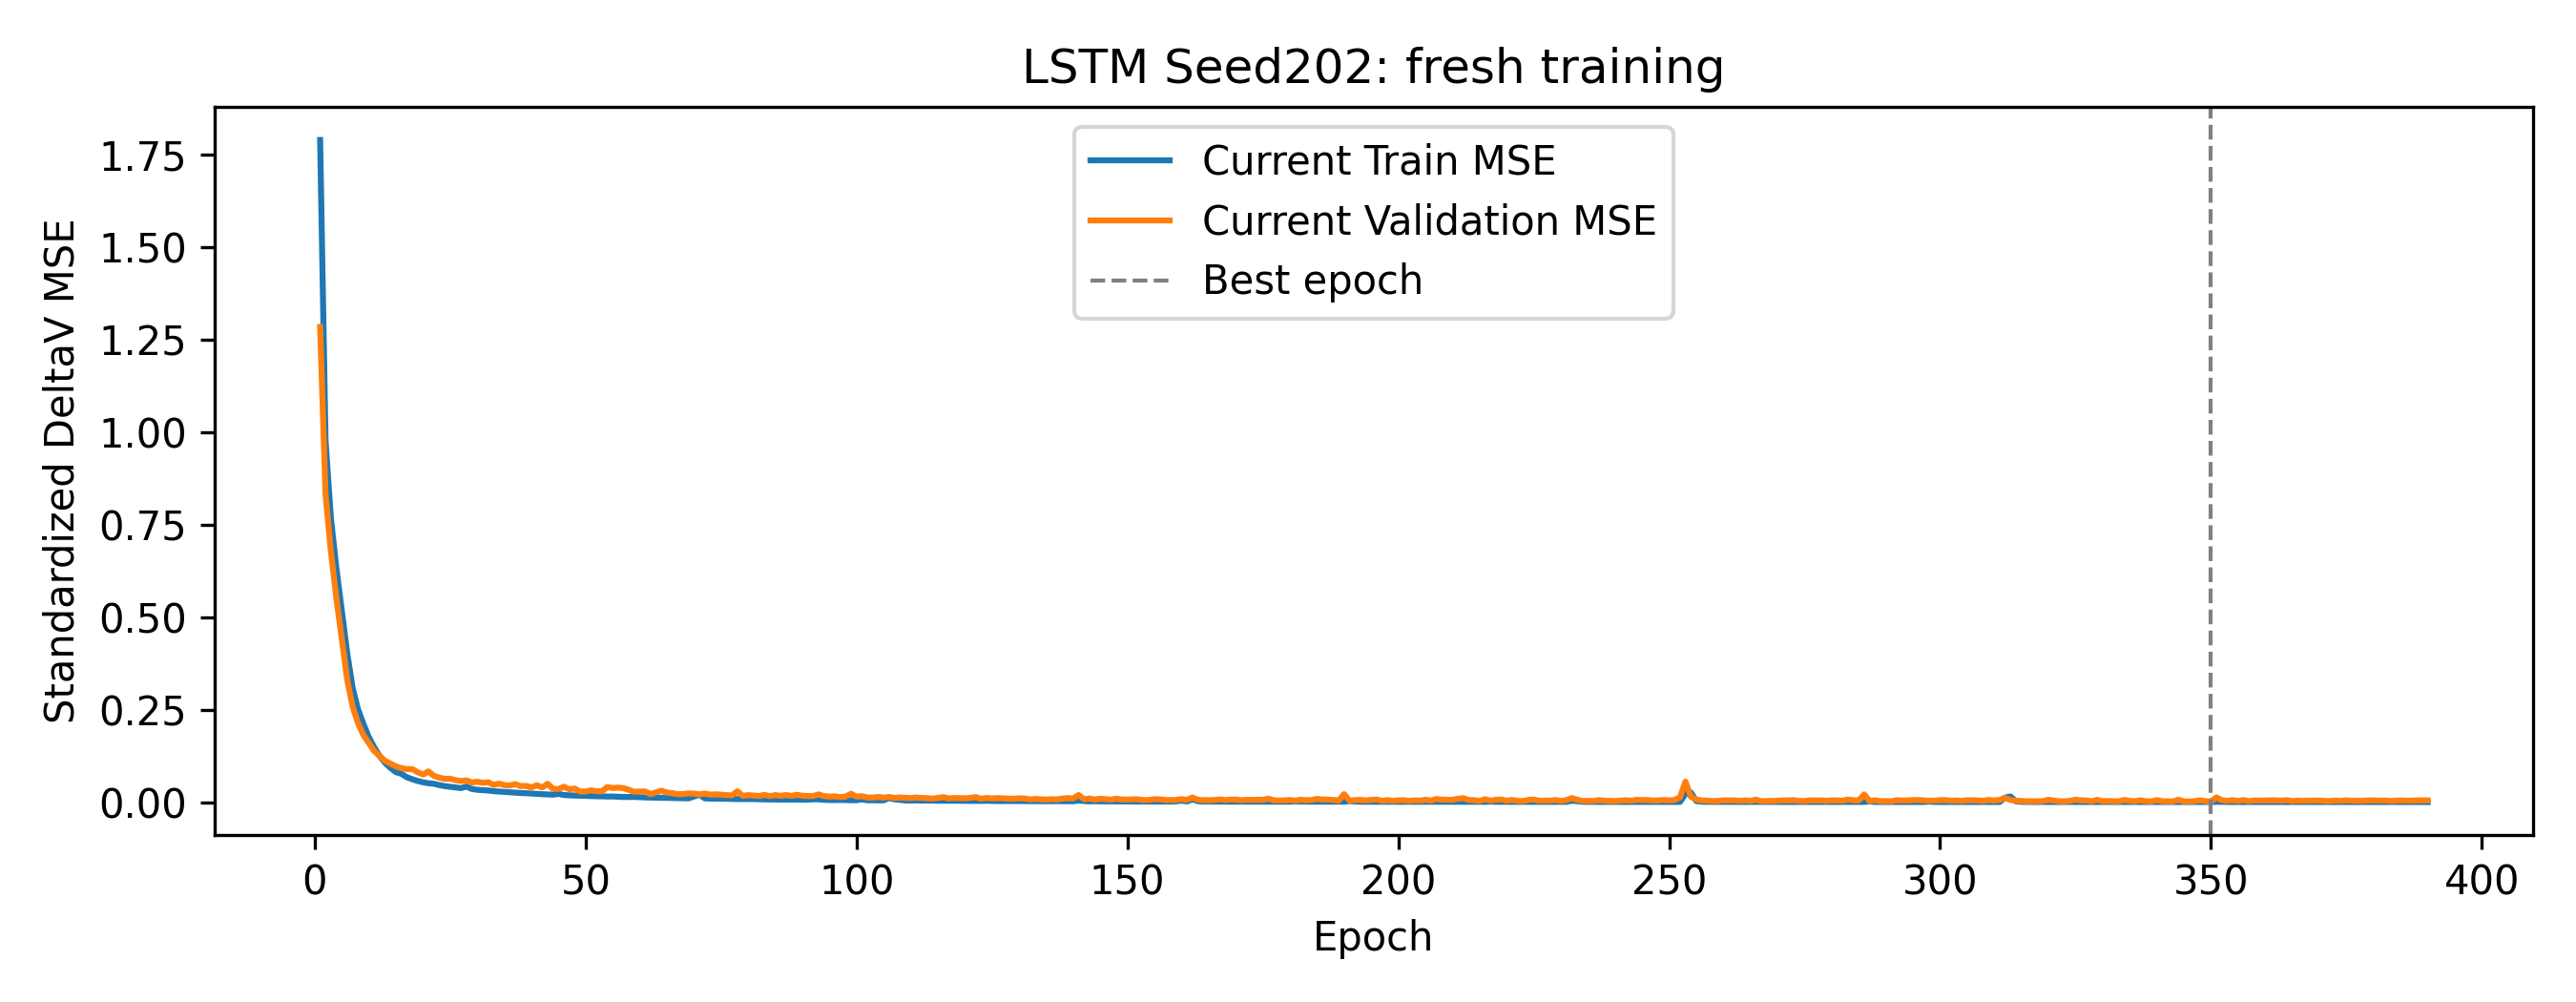

pilot LSTM Seed 202 | Epoch 2/450 | Train Loss 0.978441 | Validation Loss 0.831802 | Best Epoch 2 | Patience 0/40
pilot LSTM Seed 202 | Epoch 3/450 | Train Loss 0.765960 | Validation Loss 0.676124 | Best Epoch 3 | Patience 0/40
pilot LSTM Seed 202 | Epoch 4/450 | Train Loss 0.633018 | Validation Loss 0.551617 | Best Epoch 4 | Patience 0/40
pilot LSTM Seed 202 | Epoch 5/450 | Train Loss 0.518324 | Validation Loss 0.440383 | Best Epoch 5 | Patience 0/40
pilot LSTM Seed 202 | Epoch 6/450 | Train Loss 0.402982 | Validation Loss 0.331173 | Best Epoch 6 | Patience 0/40
pilot LSTM Seed 202 | Epoch 7/450 | Train Loss 0.308929 | Validation Loss 0.258122 | Best Epoch 7 | Patience 0/40
pilot LSTM Seed 202 | Epoch 8/450 | Train Loss 0.251077 | Validation Loss 0.213735 | Best Epoch 8 | Patience 0/40
pilot LSTM Seed 202 | Epoch 9/450 | Train Loss 0.211376 | Validation Loss 0.181500 | Best Epoch 9 | Patience 0/40
pilot LSTM Seed 202 | Epoch 10/450 | Train Loss 0.175699 | Validation Loss 0.159936 | Be

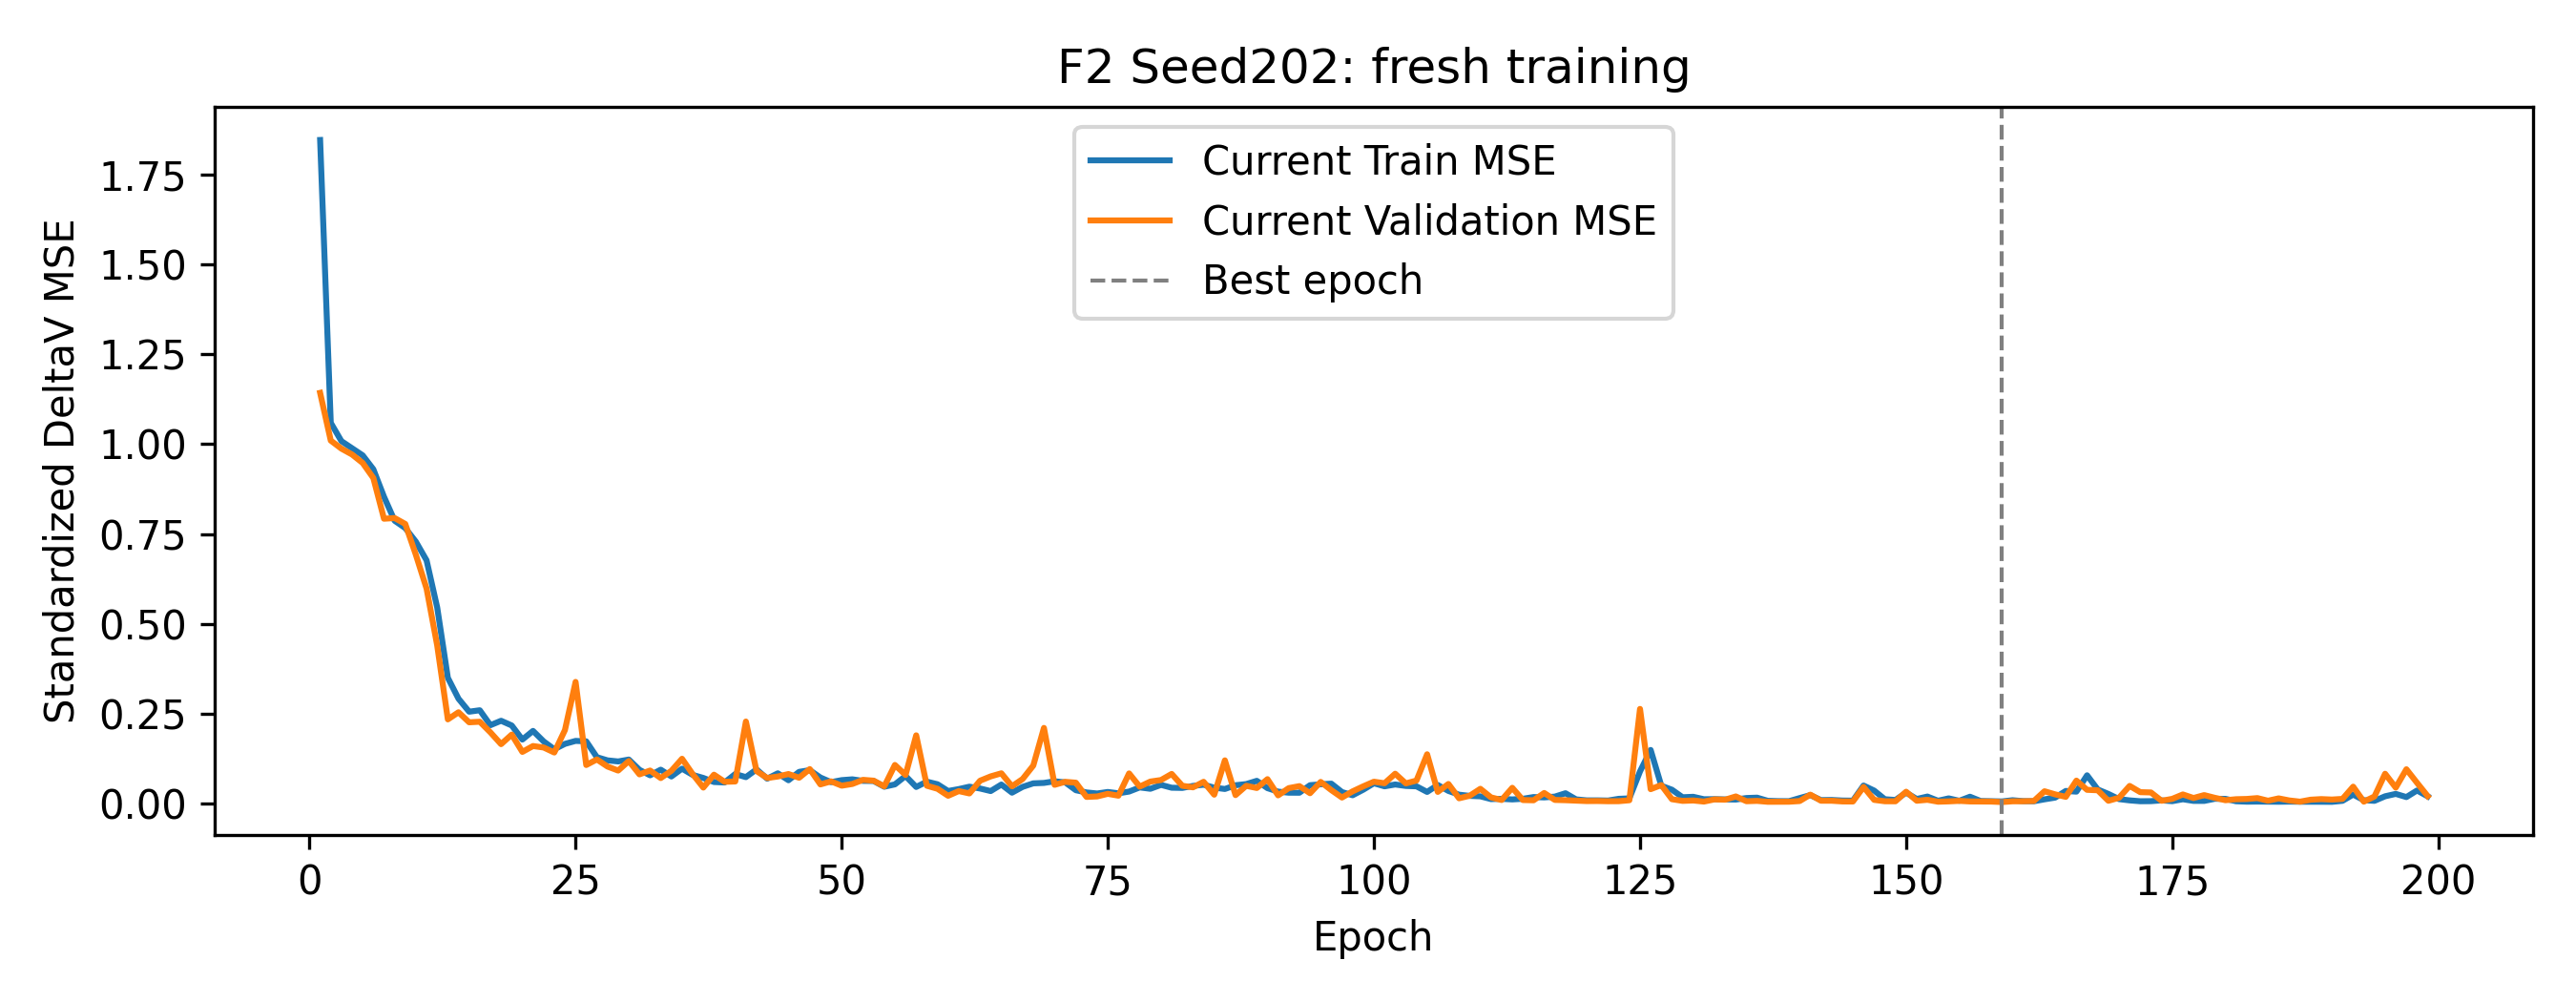

pilot F2 Seed 202 | Epoch 2/450 | Train Loss 1.059524 | Validation Loss 1.010126 | Best Epoch 2 | Patience 0/40
pilot F2 Seed 202 | Epoch 3/450 | Train Loss 1.008559 | Validation Loss 0.987617 | Best Epoch 3 | Patience 0/40
pilot F2 Seed 202 | Epoch 4/450 | Train Loss 0.988855 | Validation Loss 0.971310 | Best Epoch 4 | Patience 0/40
pilot F2 Seed 202 | Epoch 5/450 | Train Loss 0.968925 | Validation Loss 0.947636 | Best Epoch 5 | Patience 0/40
pilot F2 Seed 202 | Epoch 6/450 | Train Loss 0.930184 | Validation Loss 0.905826 | Best Epoch 6 | Patience 0/40
pilot F2 Seed 202 | Epoch 7/450 | Train Loss 0.853583 | Validation Loss 0.792388 | Best Epoch 7 | Patience 0/40
pilot F2 Seed 202 | Epoch 8/450 | Train Loss 0.786796 | Validation Loss 0.794281 | Best Epoch 7 | Patience 1/40
pilot F2 Seed 202 | Epoch 9/450 | Train Loss 0.766328 | Validation Loss 0.777863 | Best Epoch 9 | Patience 0/40
pilot F2 Seed 202 | Epoch 10/450 | Train Loss 0.728165 | Validation Loss 0.691483 | Best Epoch 10 | Pati

In [3]:
pilot(run,frame,windows,scaler,prepared,protocol)

Training formal LSTM Seed 42: 22040 parameters, fresh weights/AdamW
formal LSTM Seed 42 | Epoch 1/450 | Train Loss 1.841153 | Validation Loss 1.424414 | Best Epoch 1 | Patience 0/40


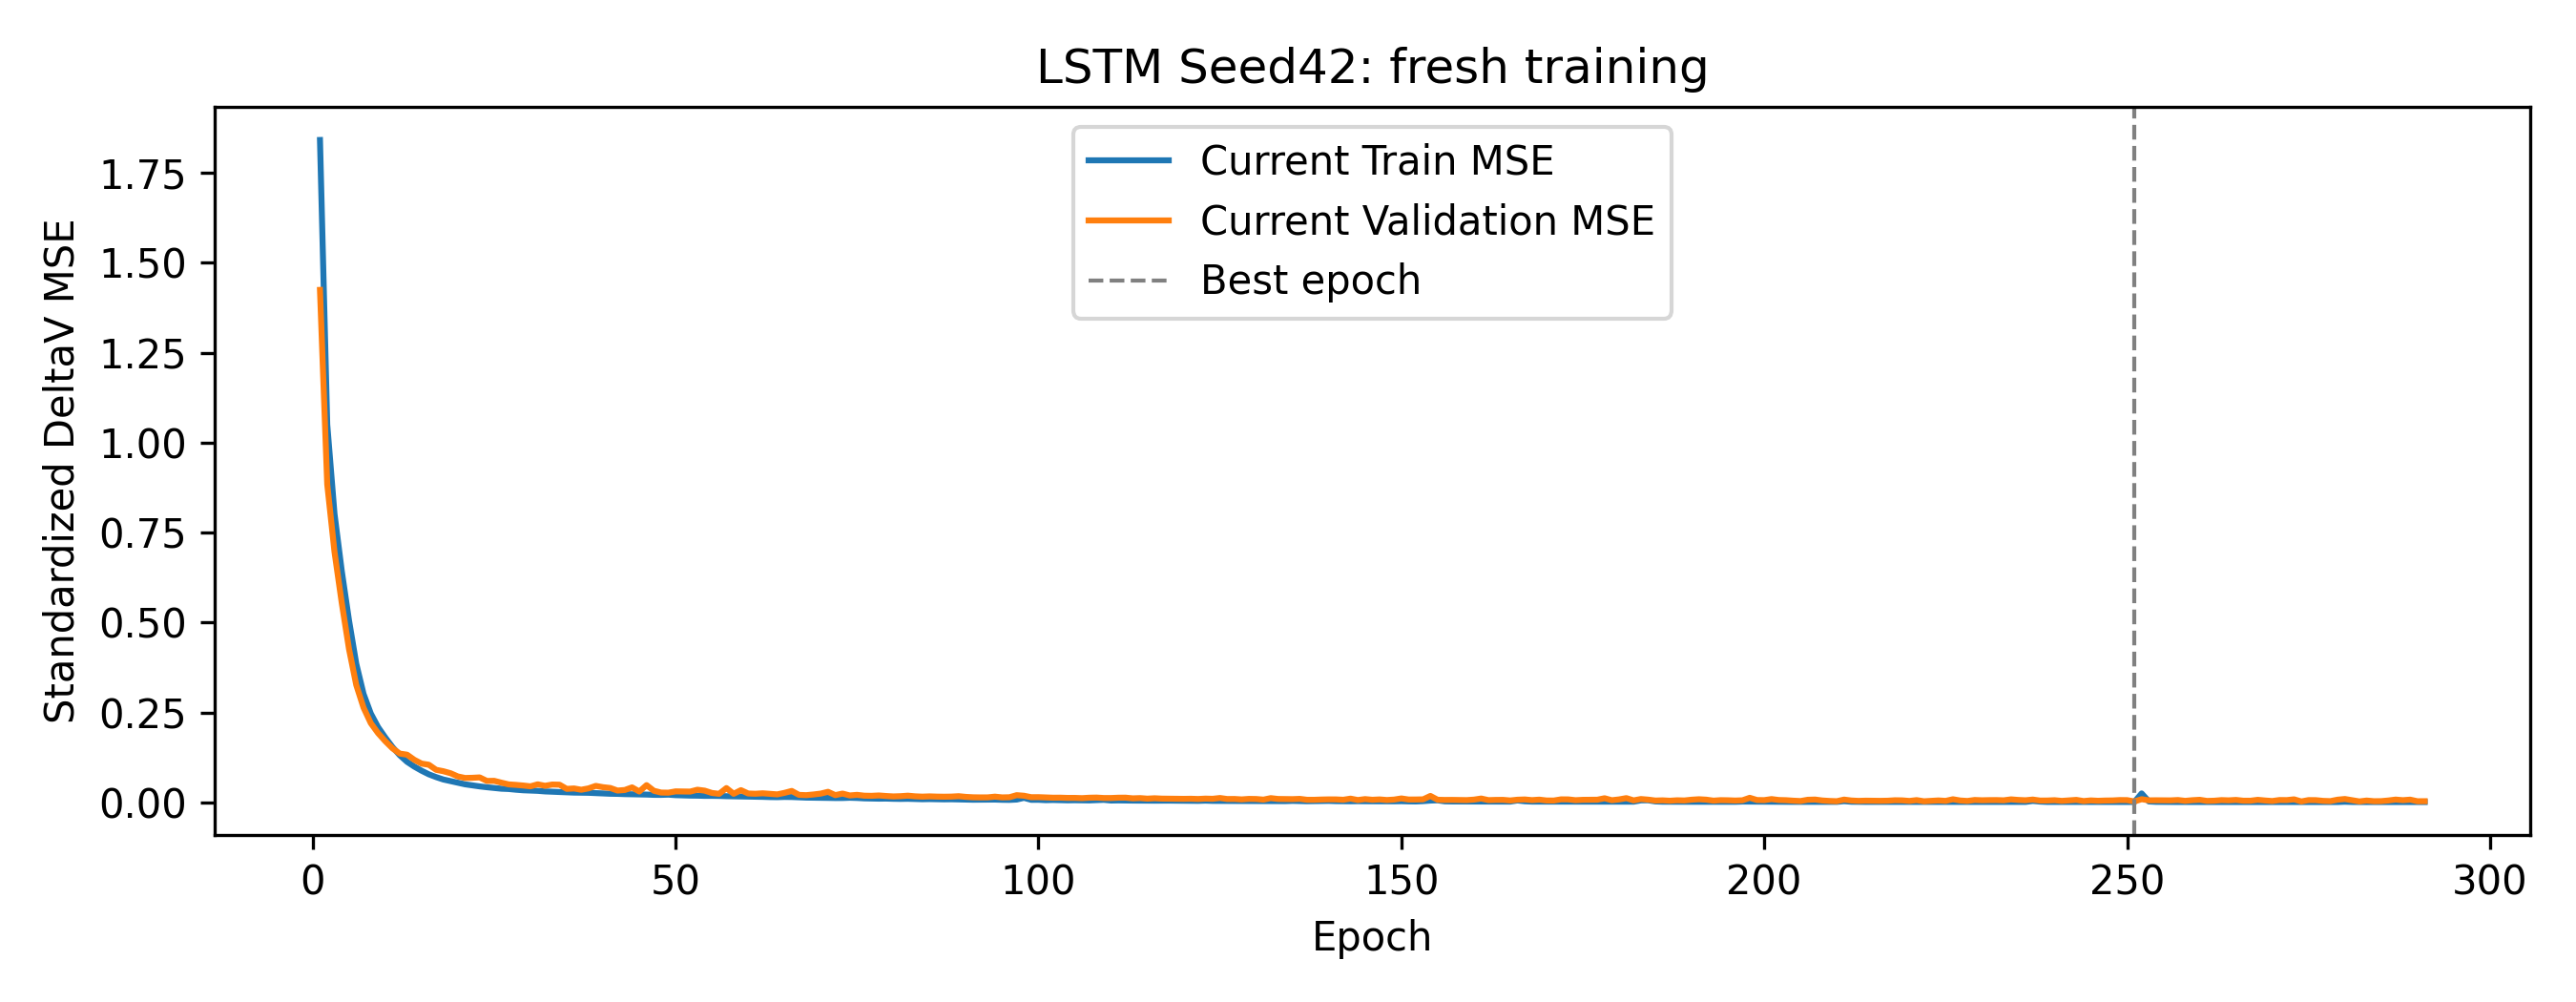

formal LSTM Seed 42 | Epoch 2/450 | Train Loss 1.050328 | Validation Loss 0.884061 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 42 | Epoch 3/450 | Train Loss 0.802237 | Validation Loss 0.696309 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 42 | Epoch 4/450 | Train Loss 0.643179 | Validation Loss 0.554623 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 42 | Epoch 5/450 | Train Loss 0.505657 | Validation Loss 0.426133 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 42 | Epoch 6/450 | Train Loss 0.385272 | Validation Loss 0.326056 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 42 | Epoch 7/450 | Train Loss 0.301513 | Validation Loss 0.263310 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 42 | Epoch 8/450 | Train Loss 0.247094 | Validation Loss 0.220212 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 42 | Epoch 9/450 | Train Loss 0.209302 | Validation Loss 0.192443 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 42 | Epoch 10/450 | Train Loss 0.180177 | Validation Loss 0.169928 | Be

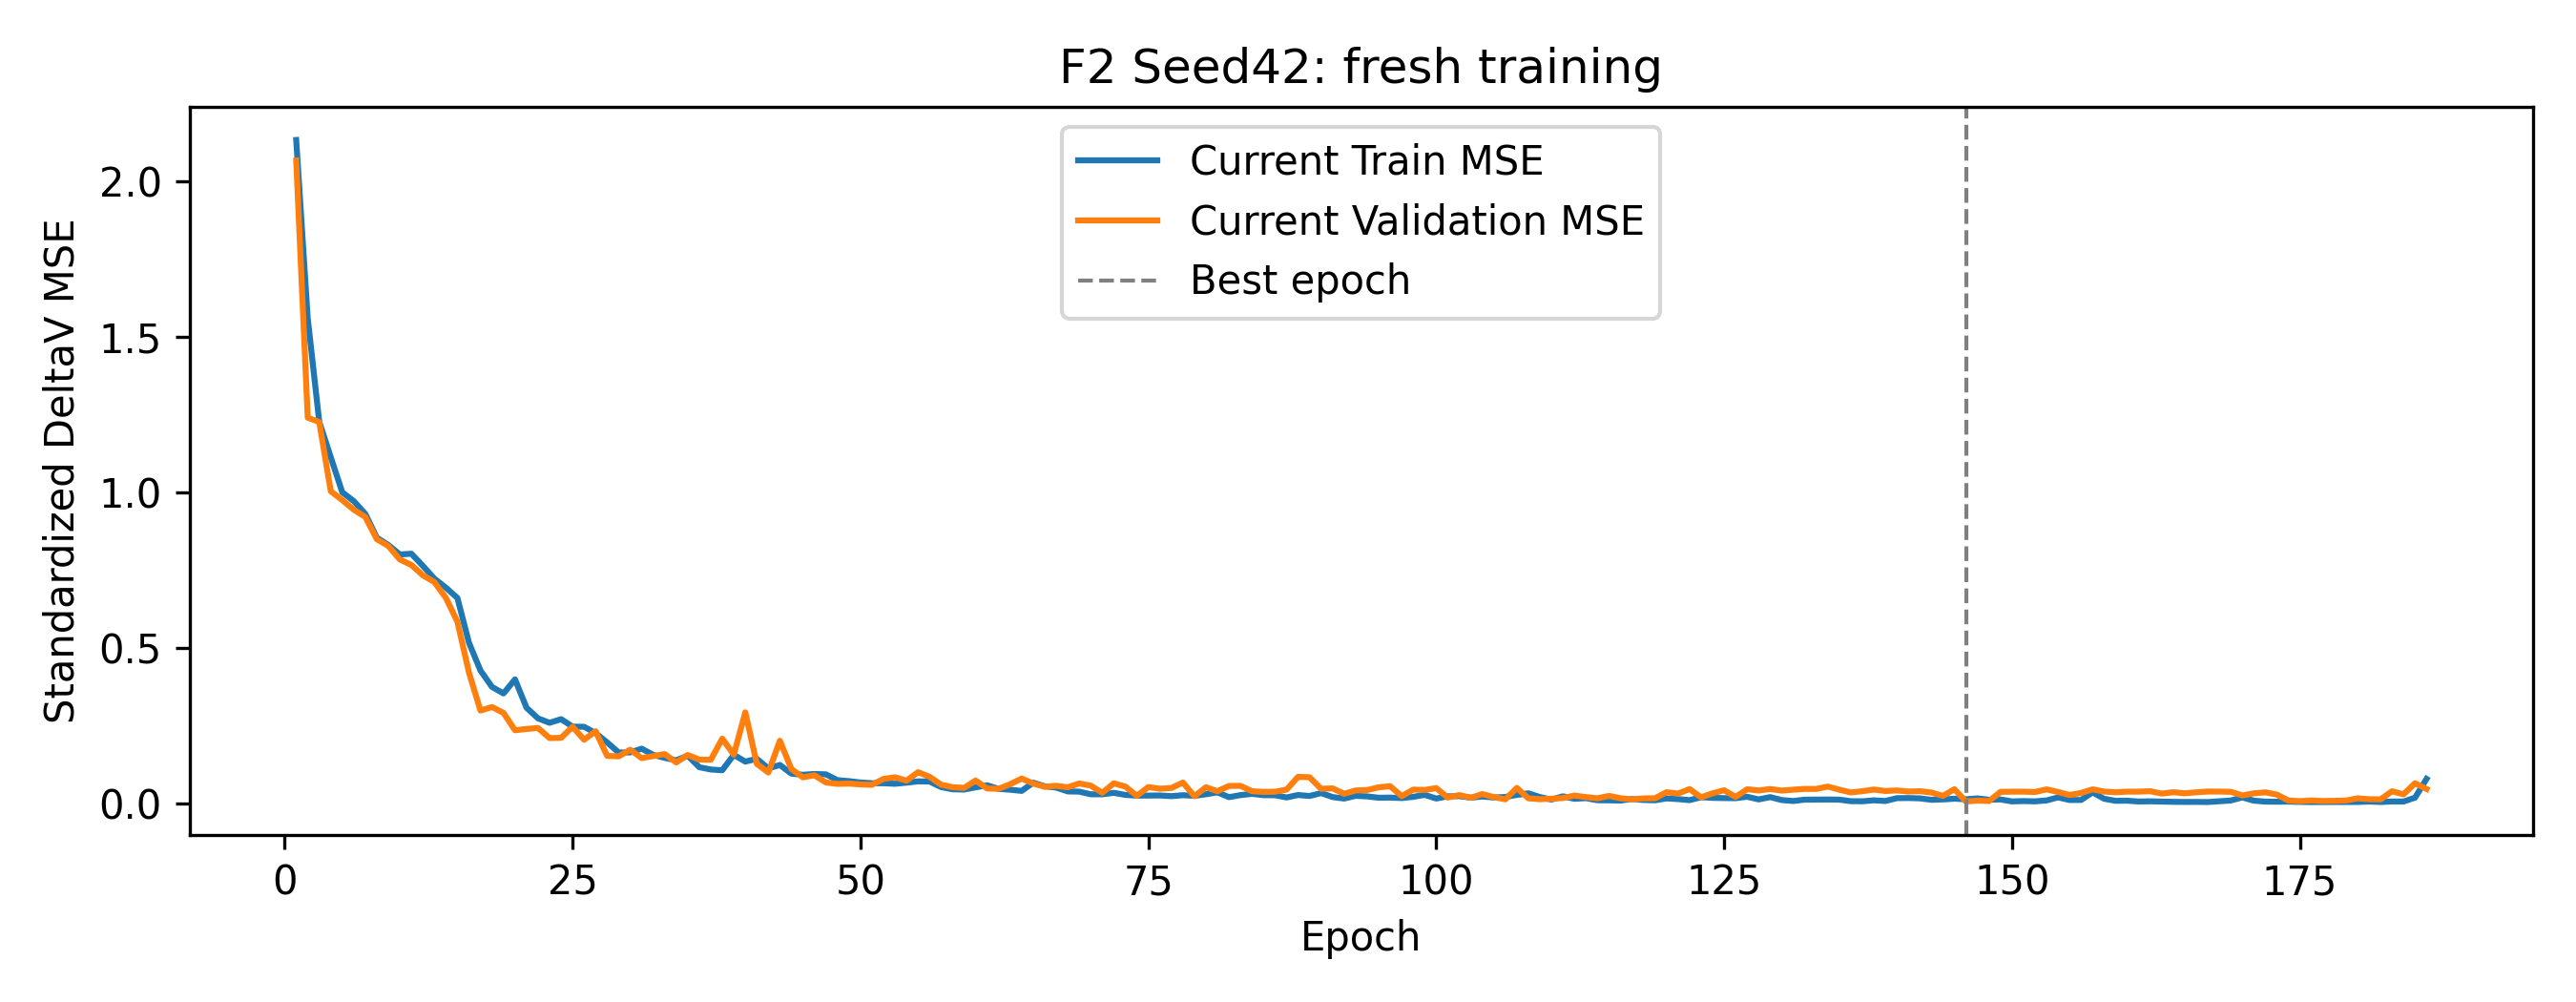

formal F2 Seed 42 | Epoch 2/450 | Train Loss 1.560351 | Validation Loss 1.240812 | Best Epoch 2 | Patience 0/40
formal F2 Seed 42 | Epoch 3/450 | Train Loss 1.227658 | Validation Loss 1.226597 | Best Epoch 3 | Patience 0/40
formal F2 Seed 42 | Epoch 4/450 | Train Loss 1.113631 | Validation Loss 1.004378 | Best Epoch 4 | Patience 0/40
formal F2 Seed 42 | Epoch 5/450 | Train Loss 1.000921 | Validation Loss 0.975687 | Best Epoch 5 | Patience 0/40
formal F2 Seed 42 | Epoch 6/450 | Train Loss 0.972549 | Validation Loss 0.944939 | Best Epoch 6 | Patience 0/40
formal F2 Seed 42 | Epoch 7/450 | Train Loss 0.931592 | Validation Loss 0.921572 | Best Epoch 7 | Patience 0/40
formal F2 Seed 42 | Epoch 8/450 | Train Loss 0.854996 | Validation Loss 0.850127 | Best Epoch 8 | Patience 0/40
formal F2 Seed 42 | Epoch 9/450 | Train Loss 0.831677 | Validation Loss 0.828390 | Best Epoch 9 | Patience 0/40
formal F2 Seed 42 | Epoch 10/450 | Train Loss 0.801053 | Validation Loss 0.784918 | Best Epoch 10 | Pati

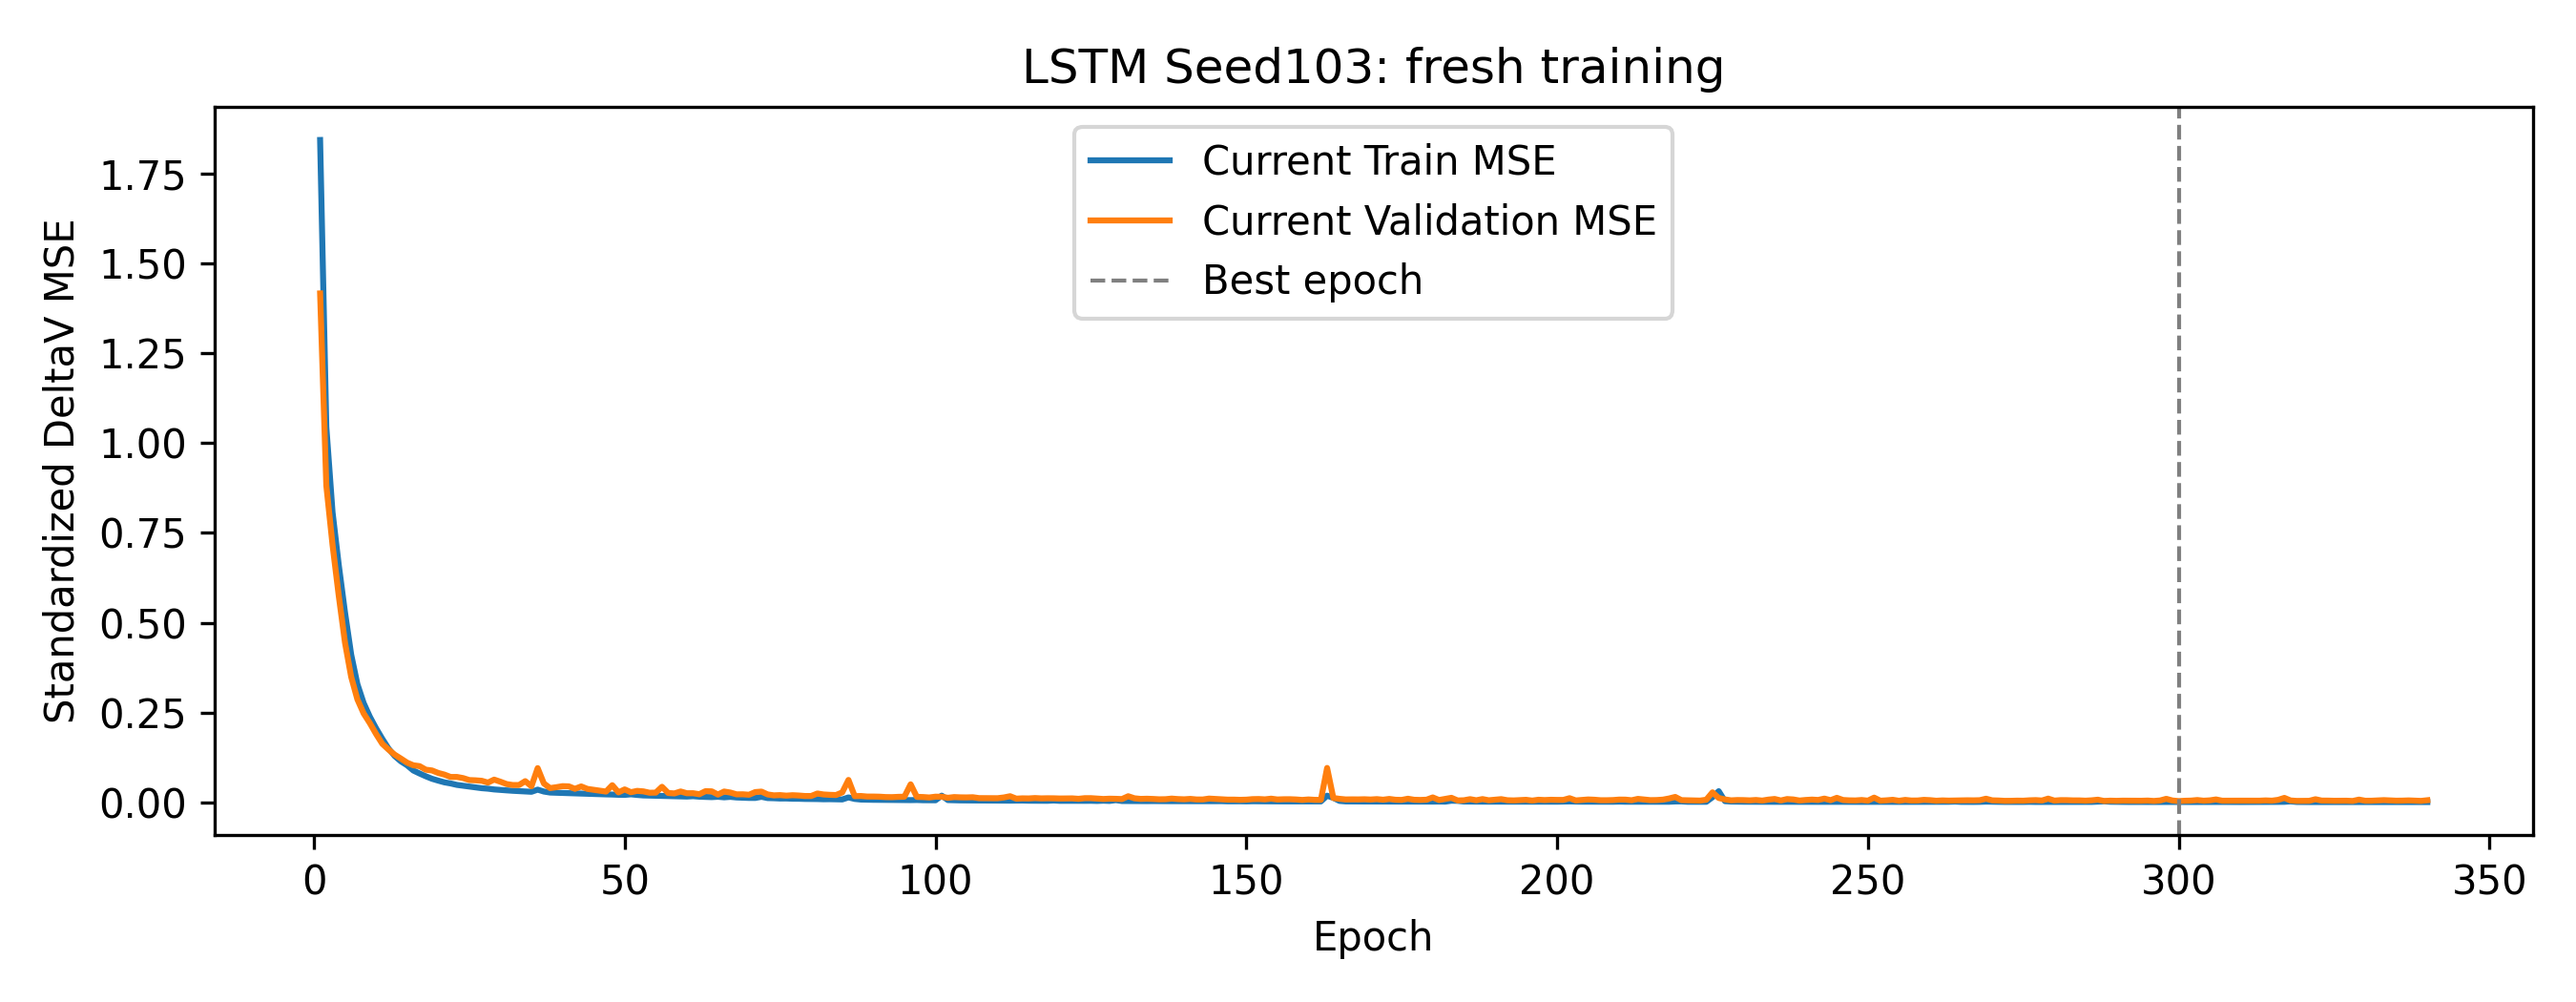

formal LSTM Seed 103 | Epoch 2/450 | Train Loss 1.045282 | Validation Loss 0.881953 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 103 | Epoch 3/450 | Train Loss 0.807917 | Validation Loss 0.716805 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 103 | Epoch 4/450 | Train Loss 0.660969 | Validation Loss 0.575084 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 103 | Epoch 5/450 | Train Loss 0.529421 | Validation Loss 0.444945 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 103 | Epoch 6/450 | Train Loss 0.411203 | Validation Loss 0.349213 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 103 | Epoch 7/450 | Train Loss 0.329120 | Validation Loss 0.286556 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 103 | Epoch 8/450 | Train Loss 0.276590 | Validation Loss 0.247627 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 103 | Epoch 9/450 | Train Loss 0.238310 | Validation Loss 0.220465 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 103 | Epoch 10/450 | Train Loss 0.206140 | Validation Loss 0.19

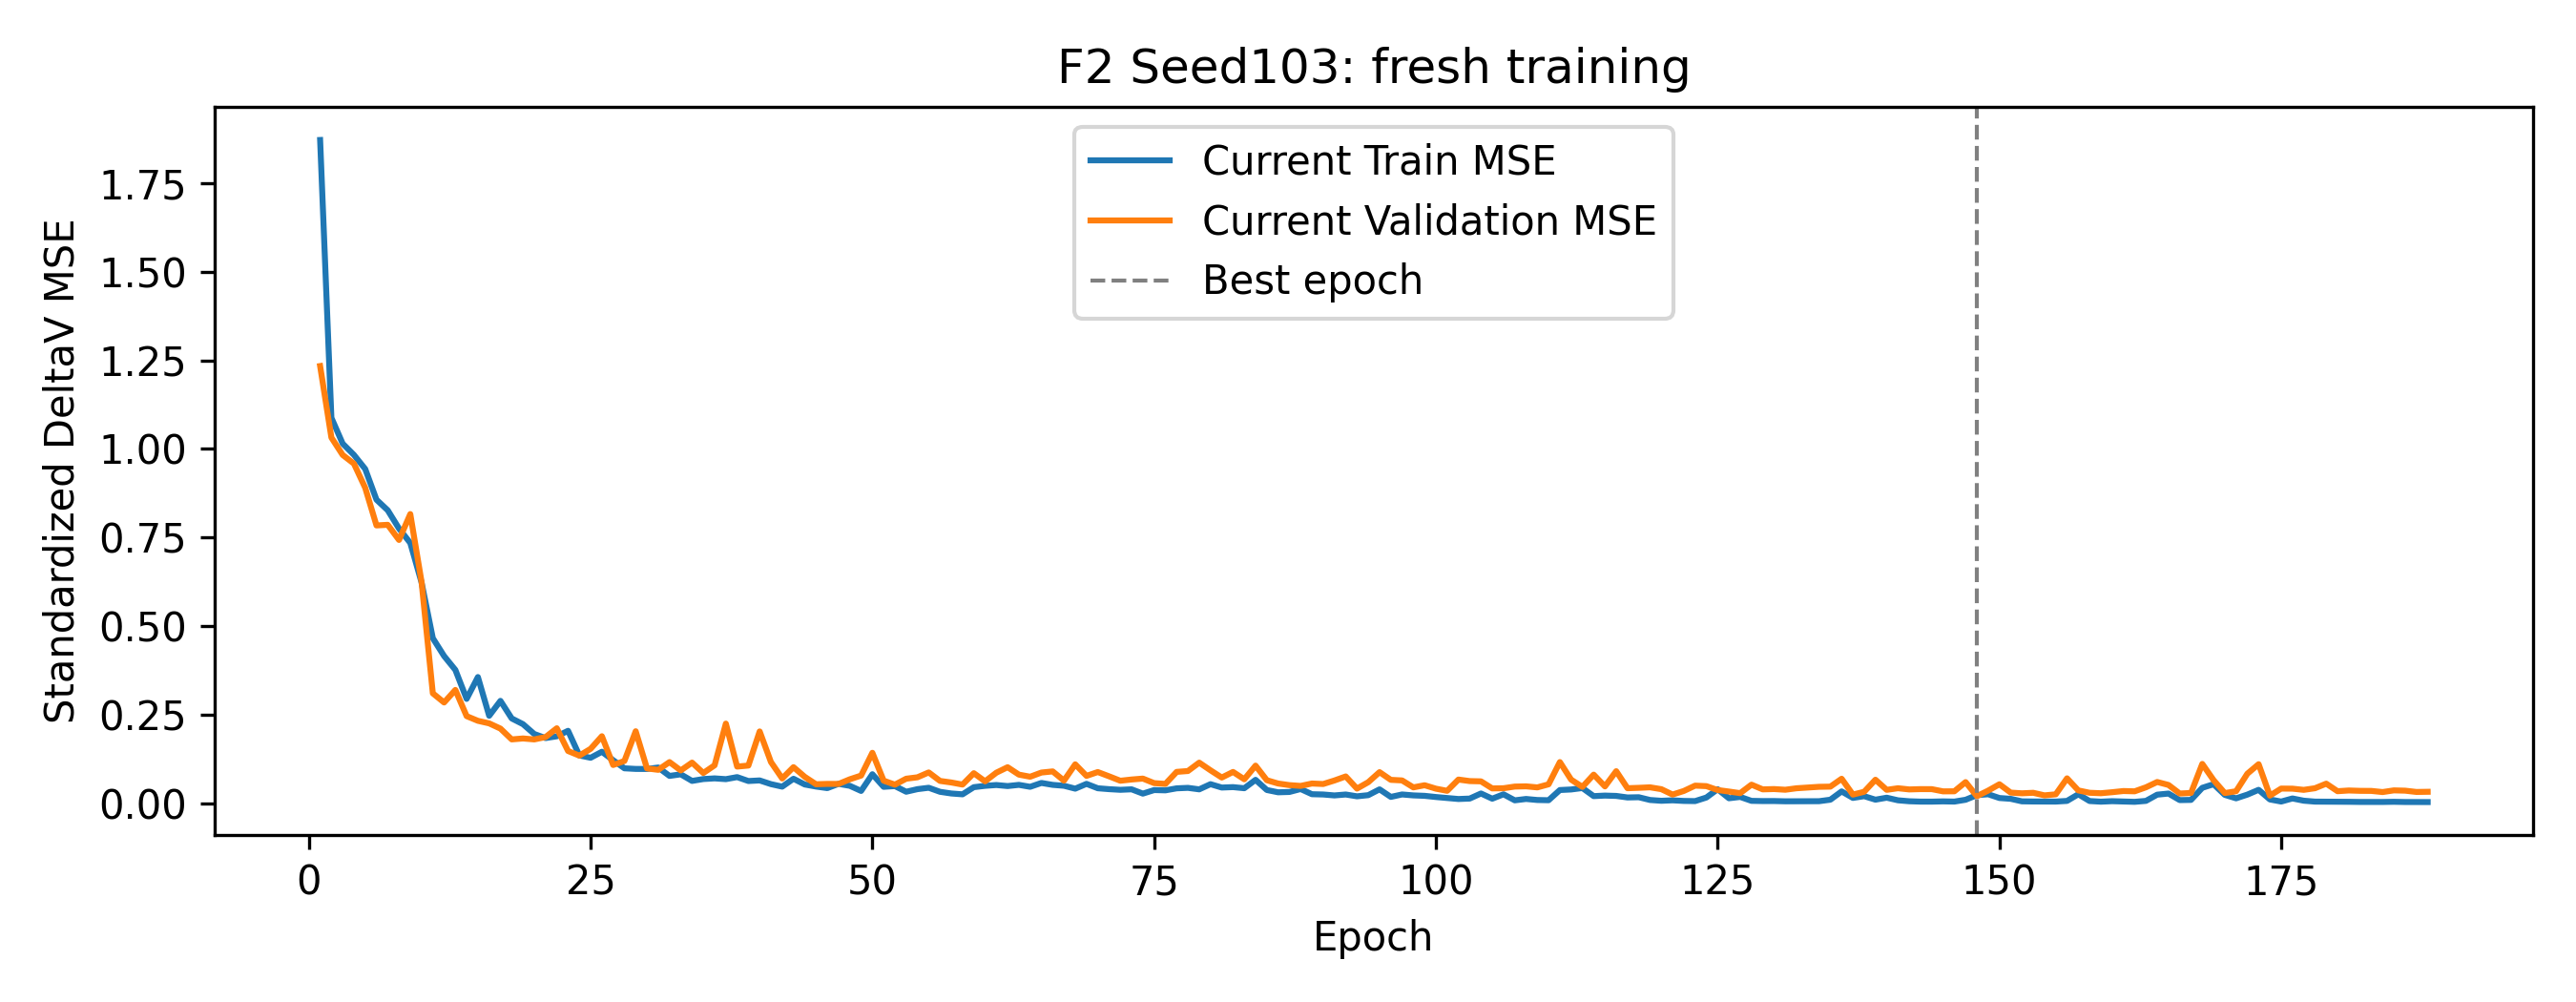

formal F2 Seed 103 | Epoch 2/450 | Train Loss 1.087749 | Validation Loss 1.031845 | Best Epoch 2 | Patience 0/40
formal F2 Seed 103 | Epoch 3/450 | Train Loss 1.014755 | Validation Loss 0.982775 | Best Epoch 3 | Patience 0/40
formal F2 Seed 103 | Epoch 4/450 | Train Loss 0.982981 | Validation Loss 0.958185 | Best Epoch 4 | Patience 0/40
formal F2 Seed 103 | Epoch 5/450 | Train Loss 0.943223 | Validation Loss 0.889964 | Best Epoch 5 | Patience 0/40
formal F2 Seed 103 | Epoch 6/450 | Train Loss 0.856565 | Validation Loss 0.783910 | Best Epoch 6 | Patience 0/40
formal F2 Seed 103 | Epoch 7/450 | Train Loss 0.826656 | Validation Loss 0.785651 | Best Epoch 6 | Patience 1/40
formal F2 Seed 103 | Epoch 8/450 | Train Loss 0.775141 | Validation Loss 0.742883 | Best Epoch 8 | Patience 0/40
formal F2 Seed 103 | Epoch 9/450 | Train Loss 0.734407 | Validation Loss 0.815996 | Best Epoch 8 | Patience 1/40
formal F2 Seed 103 | Epoch 10/450 | Train Loss 0.622930 | Validation Loss 0.624674 | Best Epoch 

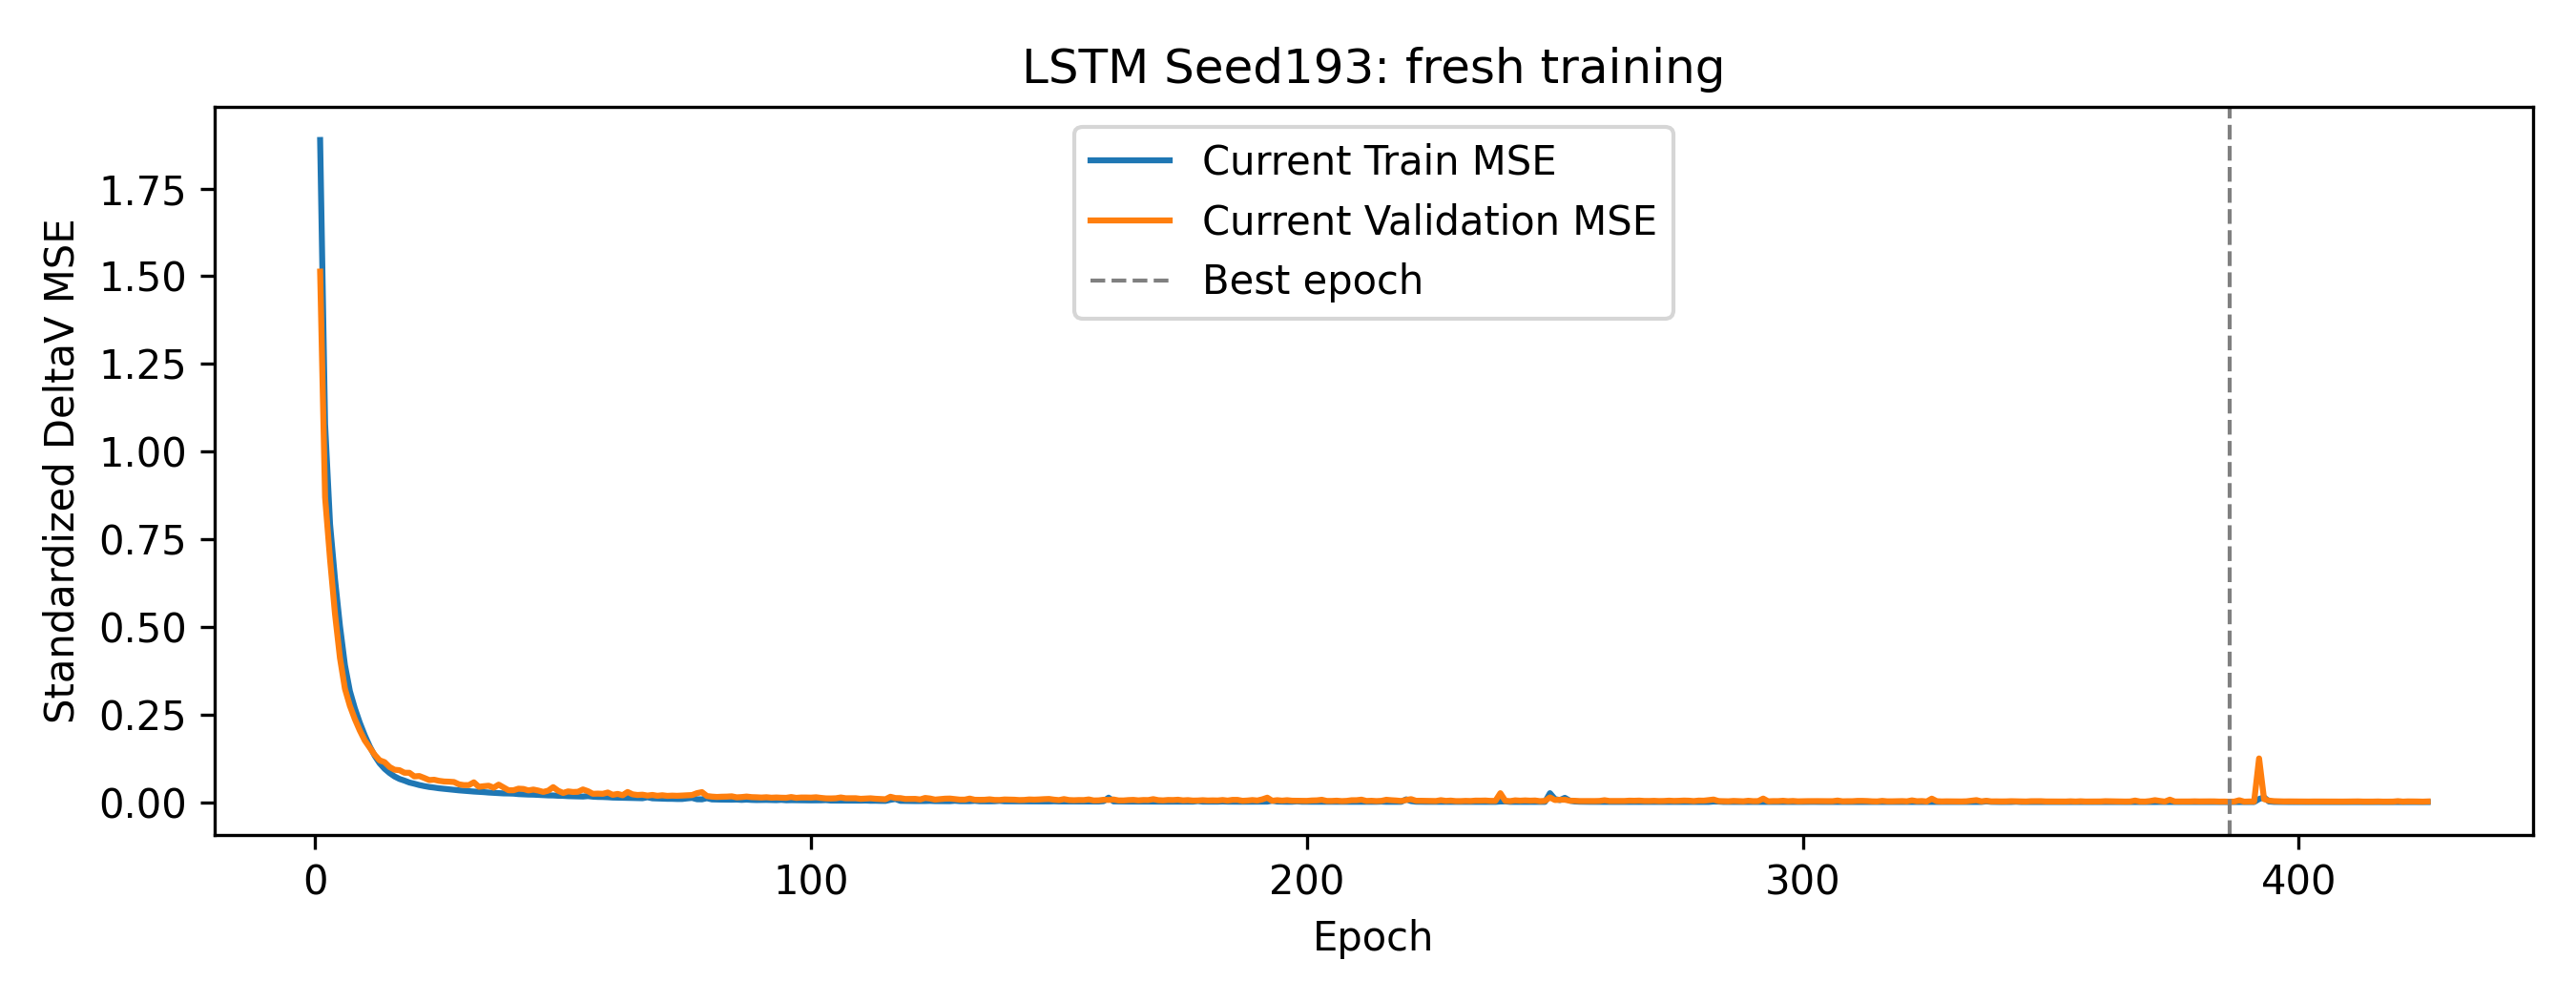

formal LSTM Seed 193 | Epoch 2/450 | Train Loss 1.078693 | Validation Loss 0.869242 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 193 | Epoch 3/450 | Train Loss 0.793059 | Validation Loss 0.692637 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 193 | Epoch 4/450 | Train Loss 0.635999 | Validation Loss 0.536776 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 193 | Epoch 5/450 | Train Loss 0.502411 | Validation Loss 0.411445 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 193 | Epoch 6/450 | Train Loss 0.391140 | Validation Loss 0.323674 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 193 | Epoch 7/450 | Train Loss 0.316834 | Validation Loss 0.274746 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 193 | Epoch 8/450 | Train Loss 0.267929 | Validation Loss 0.236937 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 193 | Epoch 9/450 | Train Loss 0.226726 | Validation Loss 0.204375 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 193 | Epoch 10/450 | Train Loss 0.190833 | Validation Loss 0.17

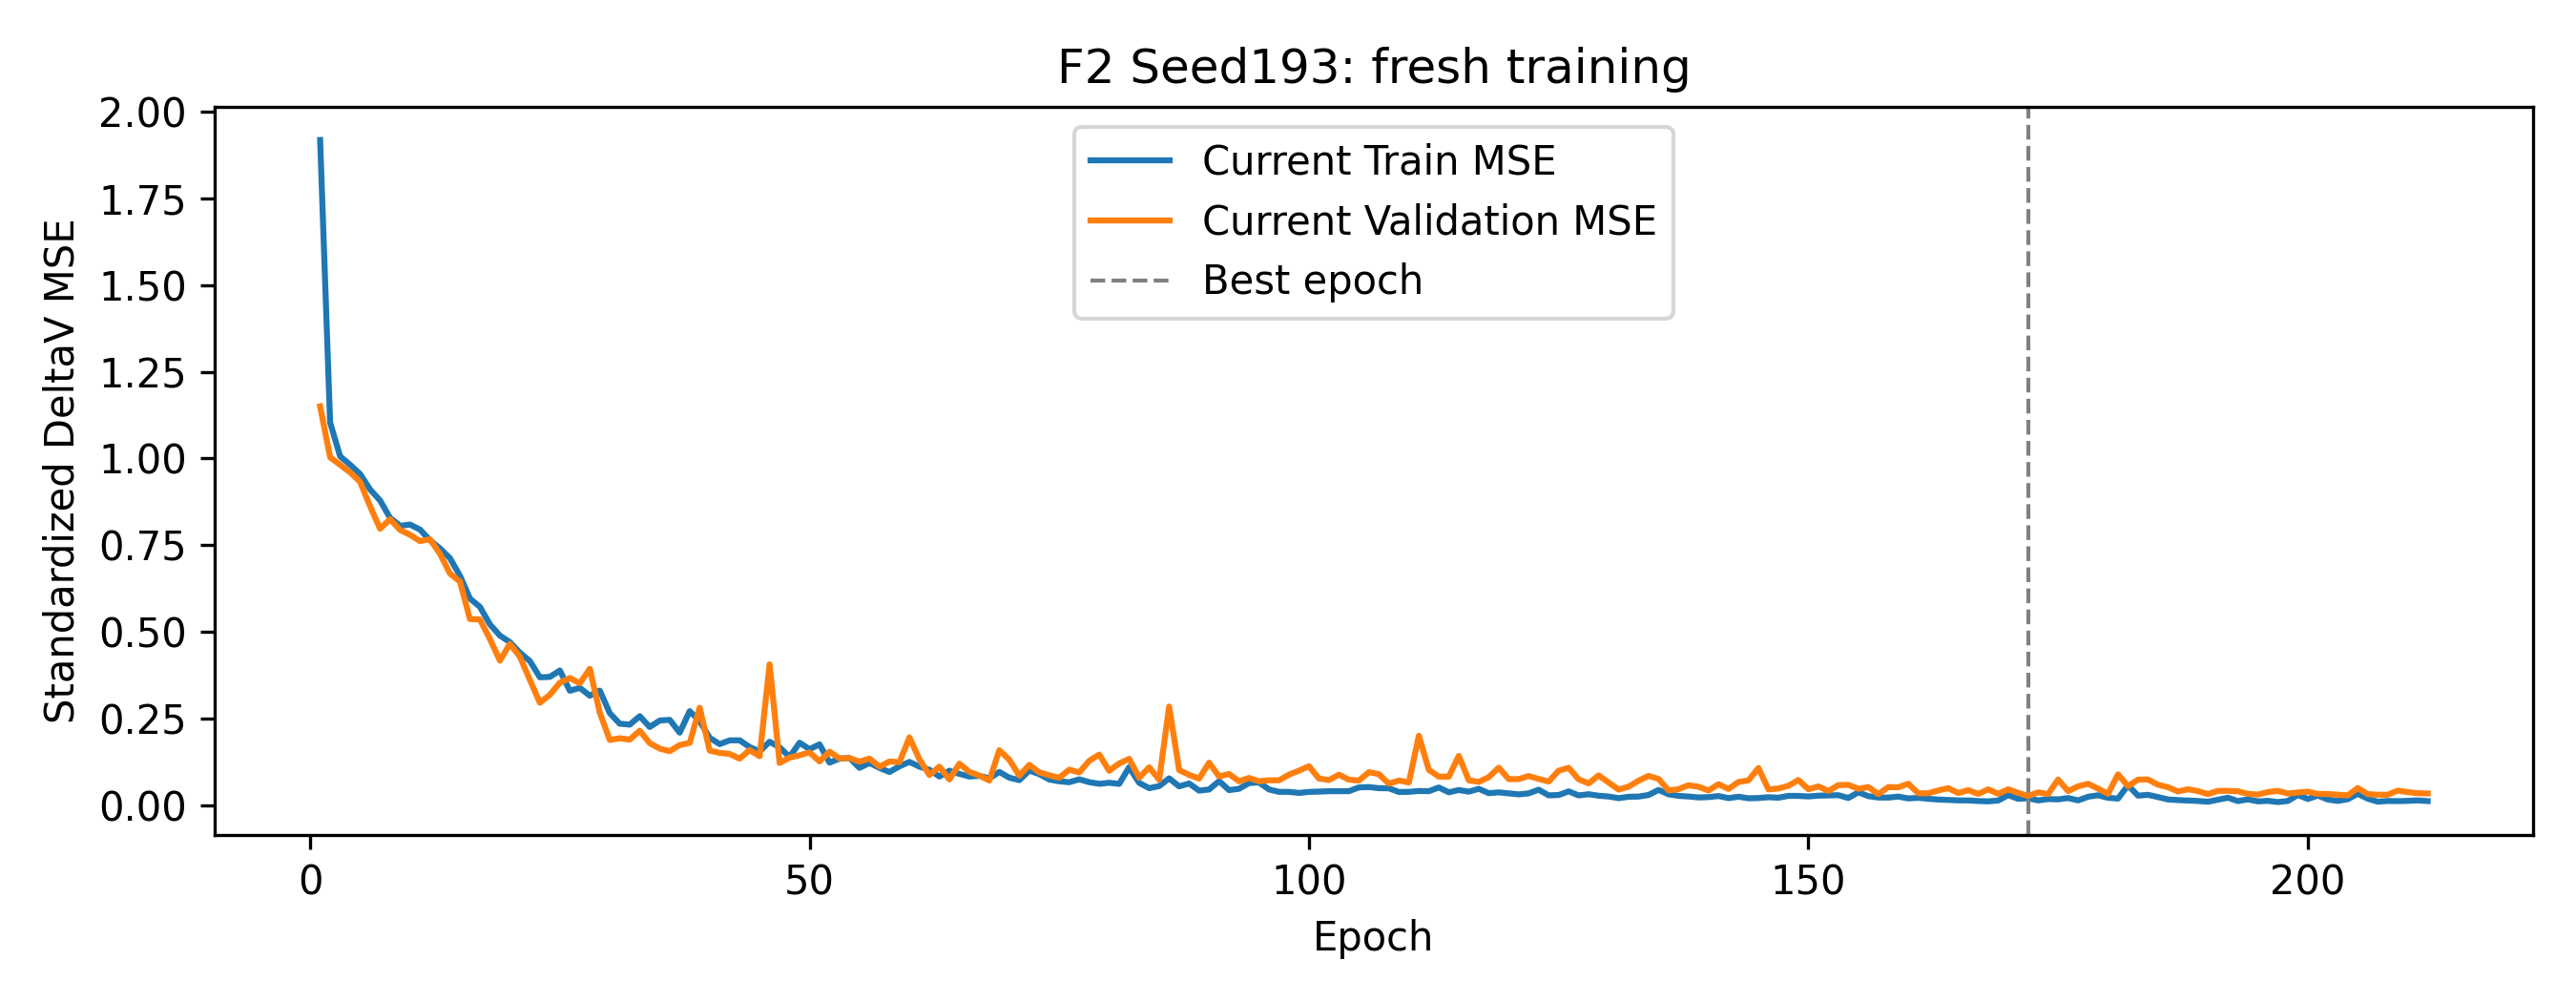

formal F2 Seed 193 | Epoch 2/450 | Train Loss 1.103404 | Validation Loss 1.003067 | Best Epoch 2 | Patience 0/40
formal F2 Seed 193 | Epoch 3/450 | Train Loss 1.005979 | Validation Loss 0.981483 | Best Epoch 3 | Patience 0/40
formal F2 Seed 193 | Epoch 4/450 | Train Loss 0.981634 | Validation Loss 0.959644 | Best Epoch 4 | Patience 0/40
formal F2 Seed 193 | Epoch 5/450 | Train Loss 0.954981 | Validation Loss 0.932245 | Best Epoch 5 | Patience 0/40
formal F2 Seed 193 | Epoch 6/450 | Train Loss 0.910336 | Validation Loss 0.861797 | Best Epoch 6 | Patience 0/40
formal F2 Seed 193 | Epoch 7/450 | Train Loss 0.878581 | Validation Loss 0.796837 | Best Epoch 7 | Patience 0/40
formal F2 Seed 193 | Epoch 8/450 | Train Loss 0.828328 | Validation Loss 0.824410 | Best Epoch 7 | Patience 1/40
formal F2 Seed 193 | Epoch 9/450 | Train Loss 0.805435 | Validation Loss 0.793565 | Best Epoch 9 | Patience 0/40
formal F2 Seed 193 | Epoch 10/450 | Train Loss 0.809038 | Validation Loss 0.779496 | Best Epoch 

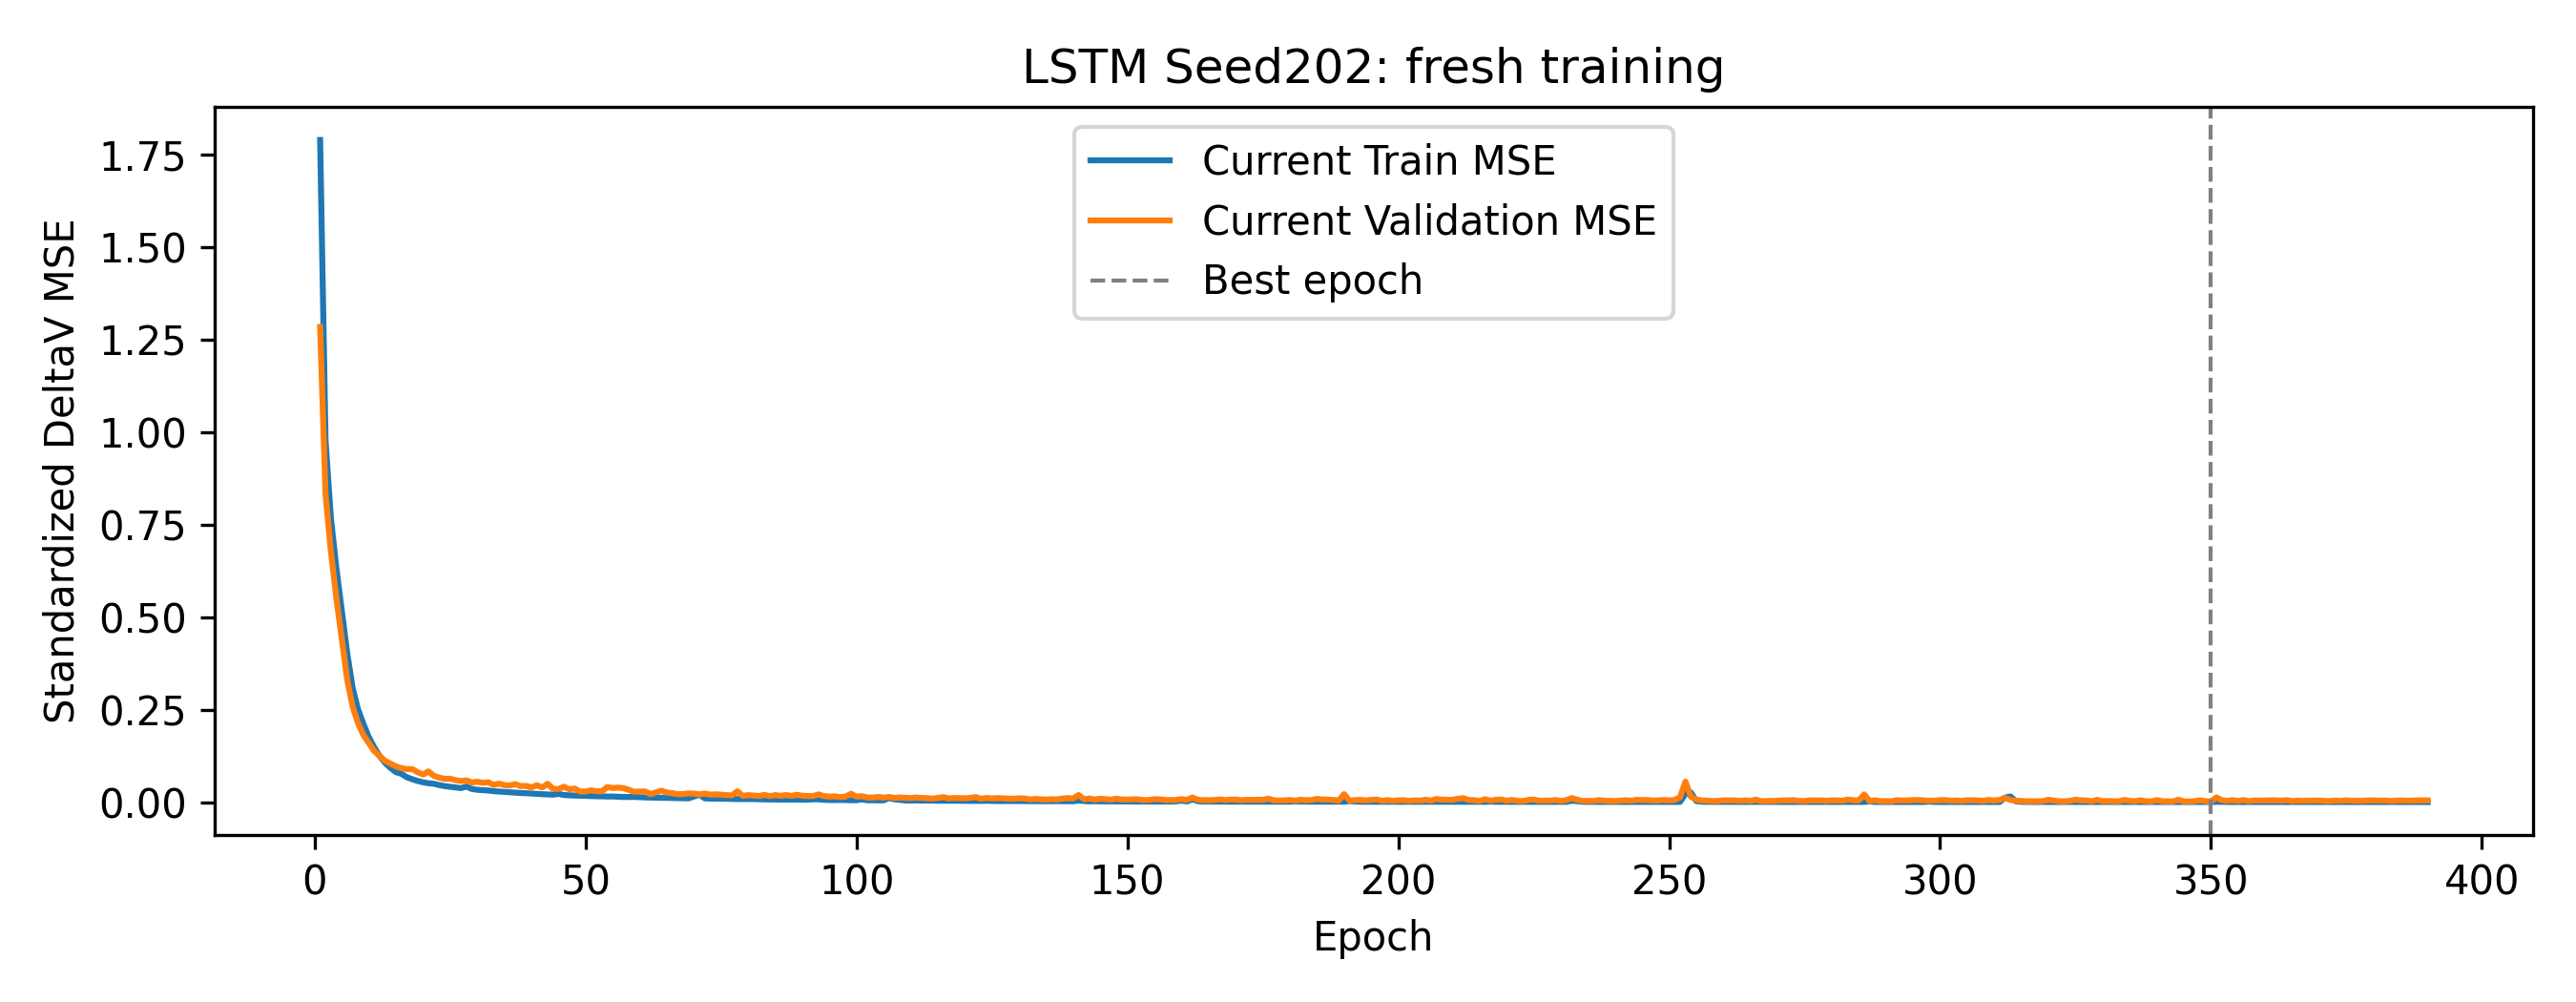

formal LSTM Seed 202 | Epoch 2/450 | Train Loss 0.978441 | Validation Loss 0.831802 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 202 | Epoch 3/450 | Train Loss 0.765960 | Validation Loss 0.676124 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 202 | Epoch 4/450 | Train Loss 0.633018 | Validation Loss 0.551617 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 202 | Epoch 5/450 | Train Loss 0.518324 | Validation Loss 0.440383 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 202 | Epoch 6/450 | Train Loss 0.402982 | Validation Loss 0.331173 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 202 | Epoch 7/450 | Train Loss 0.308929 | Validation Loss 0.258122 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 202 | Epoch 8/450 | Train Loss 0.251077 | Validation Loss 0.213735 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 202 | Epoch 9/450 | Train Loss 0.211376 | Validation Loss 0.181500 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 202 | Epoch 10/450 | Train Loss 0.175699 | Validation Loss 0.15

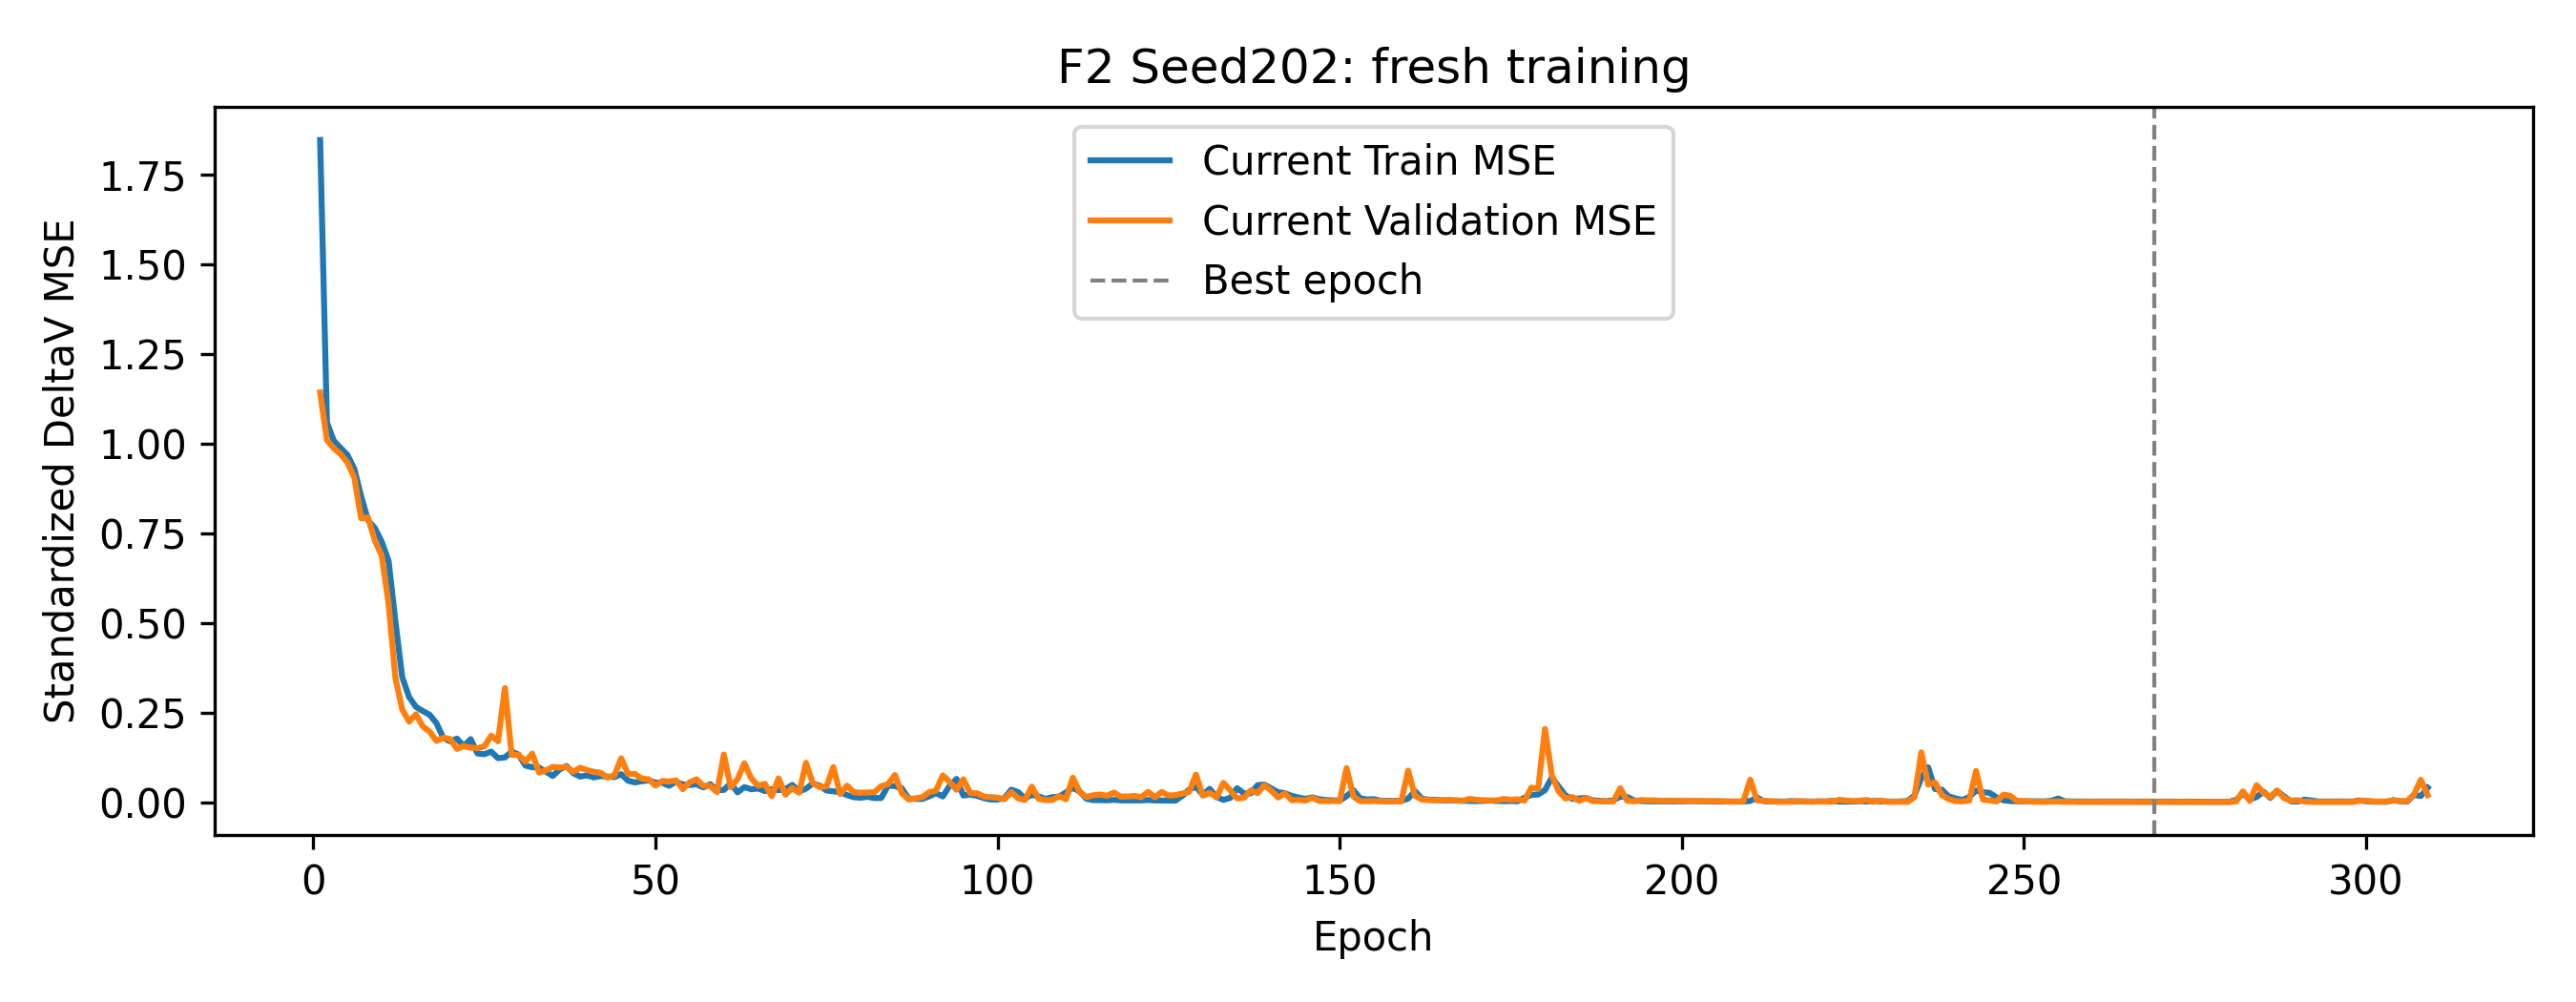

formal F2 Seed 202 | Epoch 2/450 | Train Loss 1.059524 | Validation Loss 1.010126 | Best Epoch 2 | Patience 0/40
formal F2 Seed 202 | Epoch 3/450 | Train Loss 1.008559 | Validation Loss 0.987617 | Best Epoch 3 | Patience 0/40
formal F2 Seed 202 | Epoch 4/450 | Train Loss 0.988855 | Validation Loss 0.971310 | Best Epoch 4 | Patience 0/40
formal F2 Seed 202 | Epoch 5/450 | Train Loss 0.968925 | Validation Loss 0.947636 | Best Epoch 5 | Patience 0/40
formal F2 Seed 202 | Epoch 6/450 | Train Loss 0.930184 | Validation Loss 0.905830 | Best Epoch 6 | Patience 0/40
formal F2 Seed 202 | Epoch 7/450 | Train Loss 0.853581 | Validation Loss 0.792430 | Best Epoch 7 | Patience 0/40
formal F2 Seed 202 | Epoch 8/450 | Train Loss 0.786708 | Validation Loss 0.794179 | Best Epoch 7 | Patience 1/40
formal F2 Seed 202 | Epoch 9/450 | Train Loss 0.765293 | Validation Loss 0.730126 | Best Epoch 9 | Patience 0/40
formal F2 Seed 202 | Epoch 10/450 | Train Loss 0.727451 | Validation Loss 0.688707 | Best Epoch 

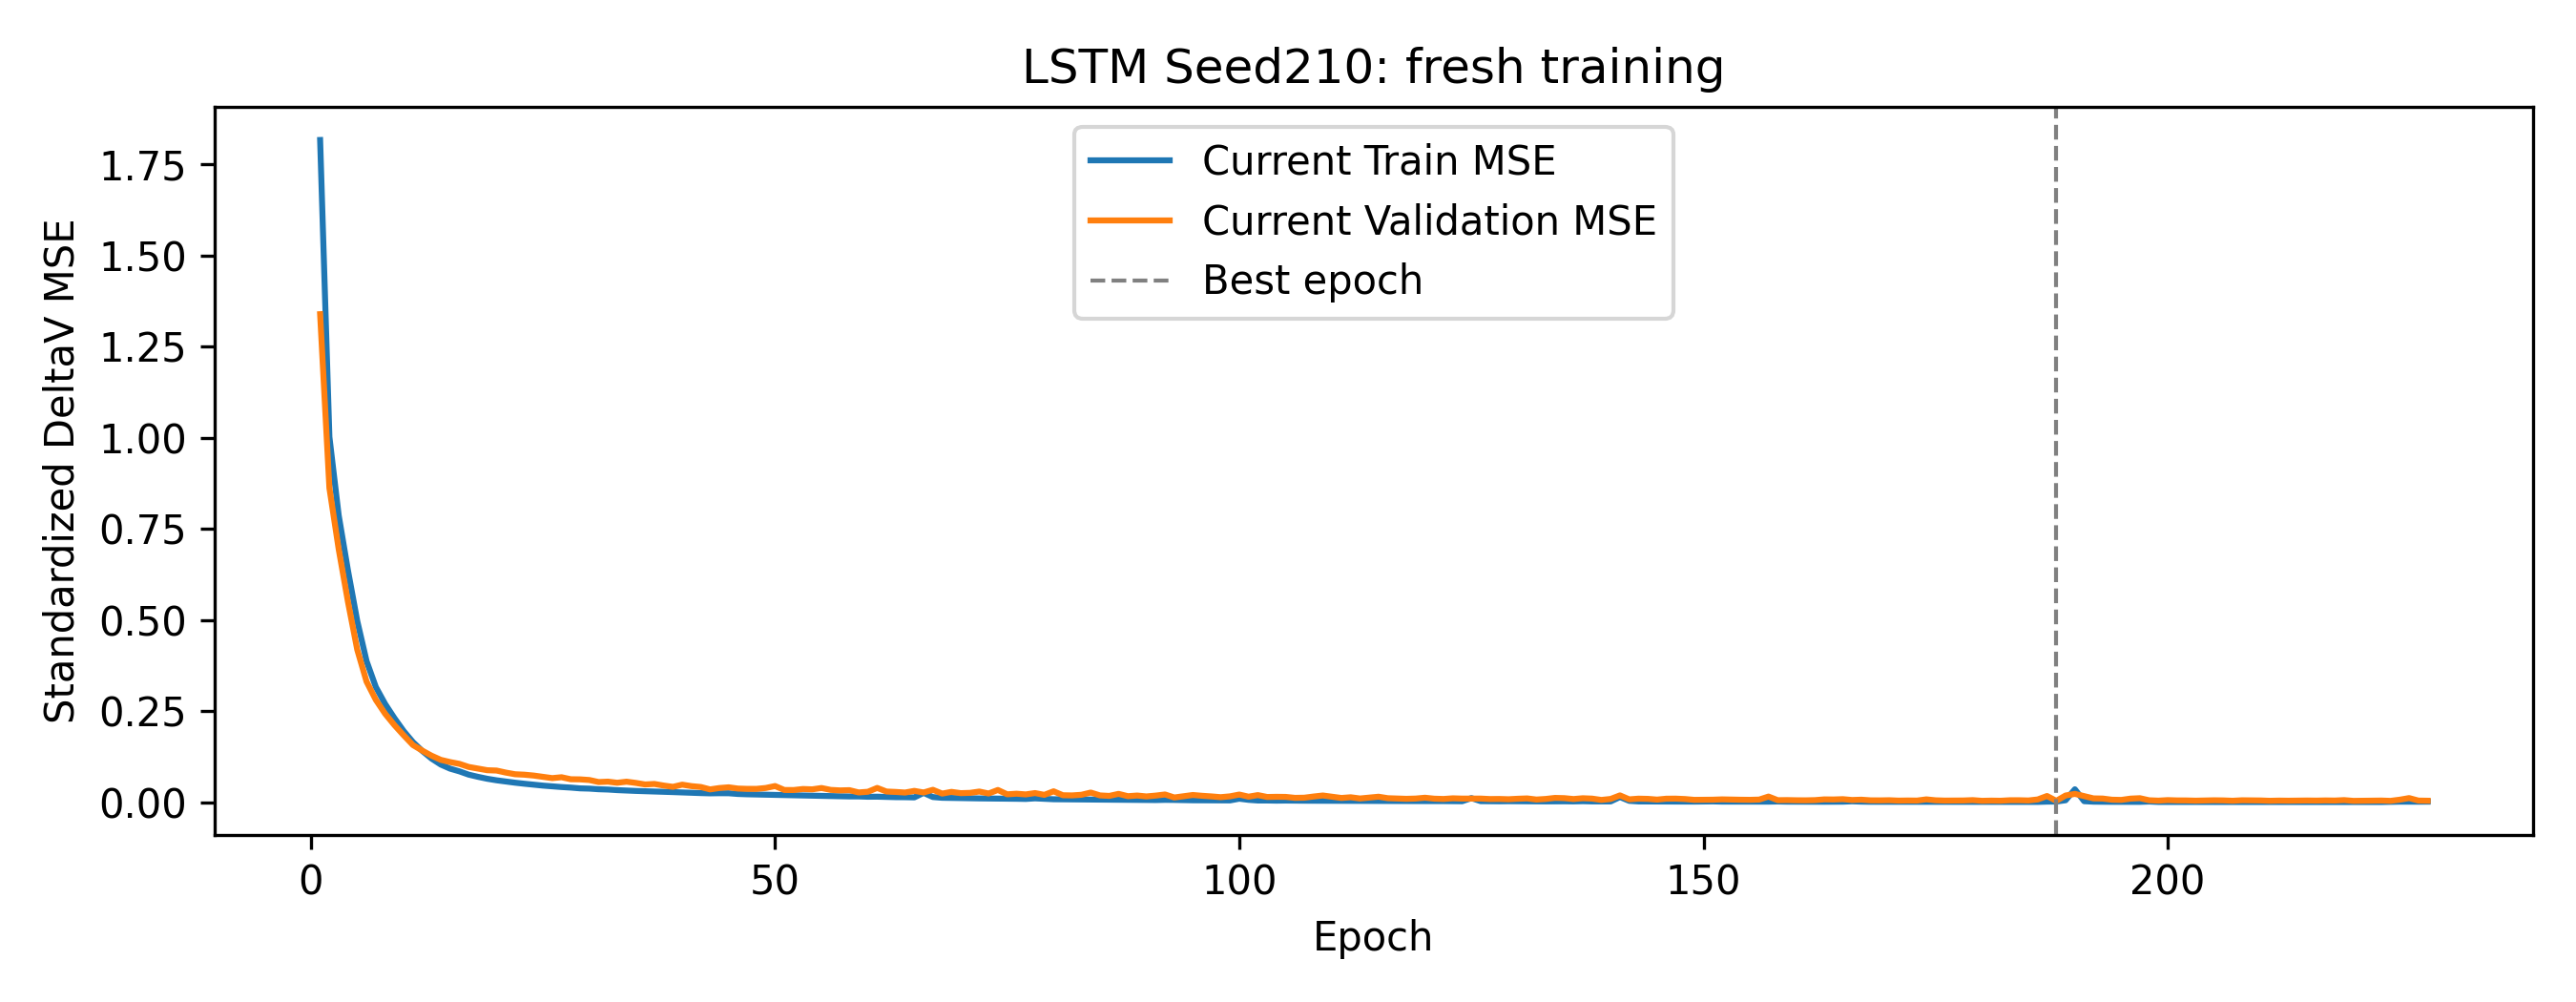

formal LSTM Seed 210 | Epoch 2/450 | Train Loss 1.002508 | Validation Loss 0.862387 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 210 | Epoch 3/450 | Train Loss 0.787525 | Validation Loss 0.694878 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 210 | Epoch 4/450 | Train Loss 0.636137 | Validation Loss 0.550118 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 210 | Epoch 5/450 | Train Loss 0.497815 | Validation Loss 0.419018 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 210 | Epoch 6/450 | Train Loss 0.387899 | Validation Loss 0.331501 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 210 | Epoch 7/450 | Train Loss 0.316730 | Validation Loss 0.281545 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 210 | Epoch 8/450 | Train Loss 0.270326 | Validation Loss 0.243527 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 210 | Epoch 9/450 | Train Loss 0.231469 | Validation Loss 0.212325 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 210 | Epoch 10/450 | Train Loss 0.195835 | Validation Loss 0.18

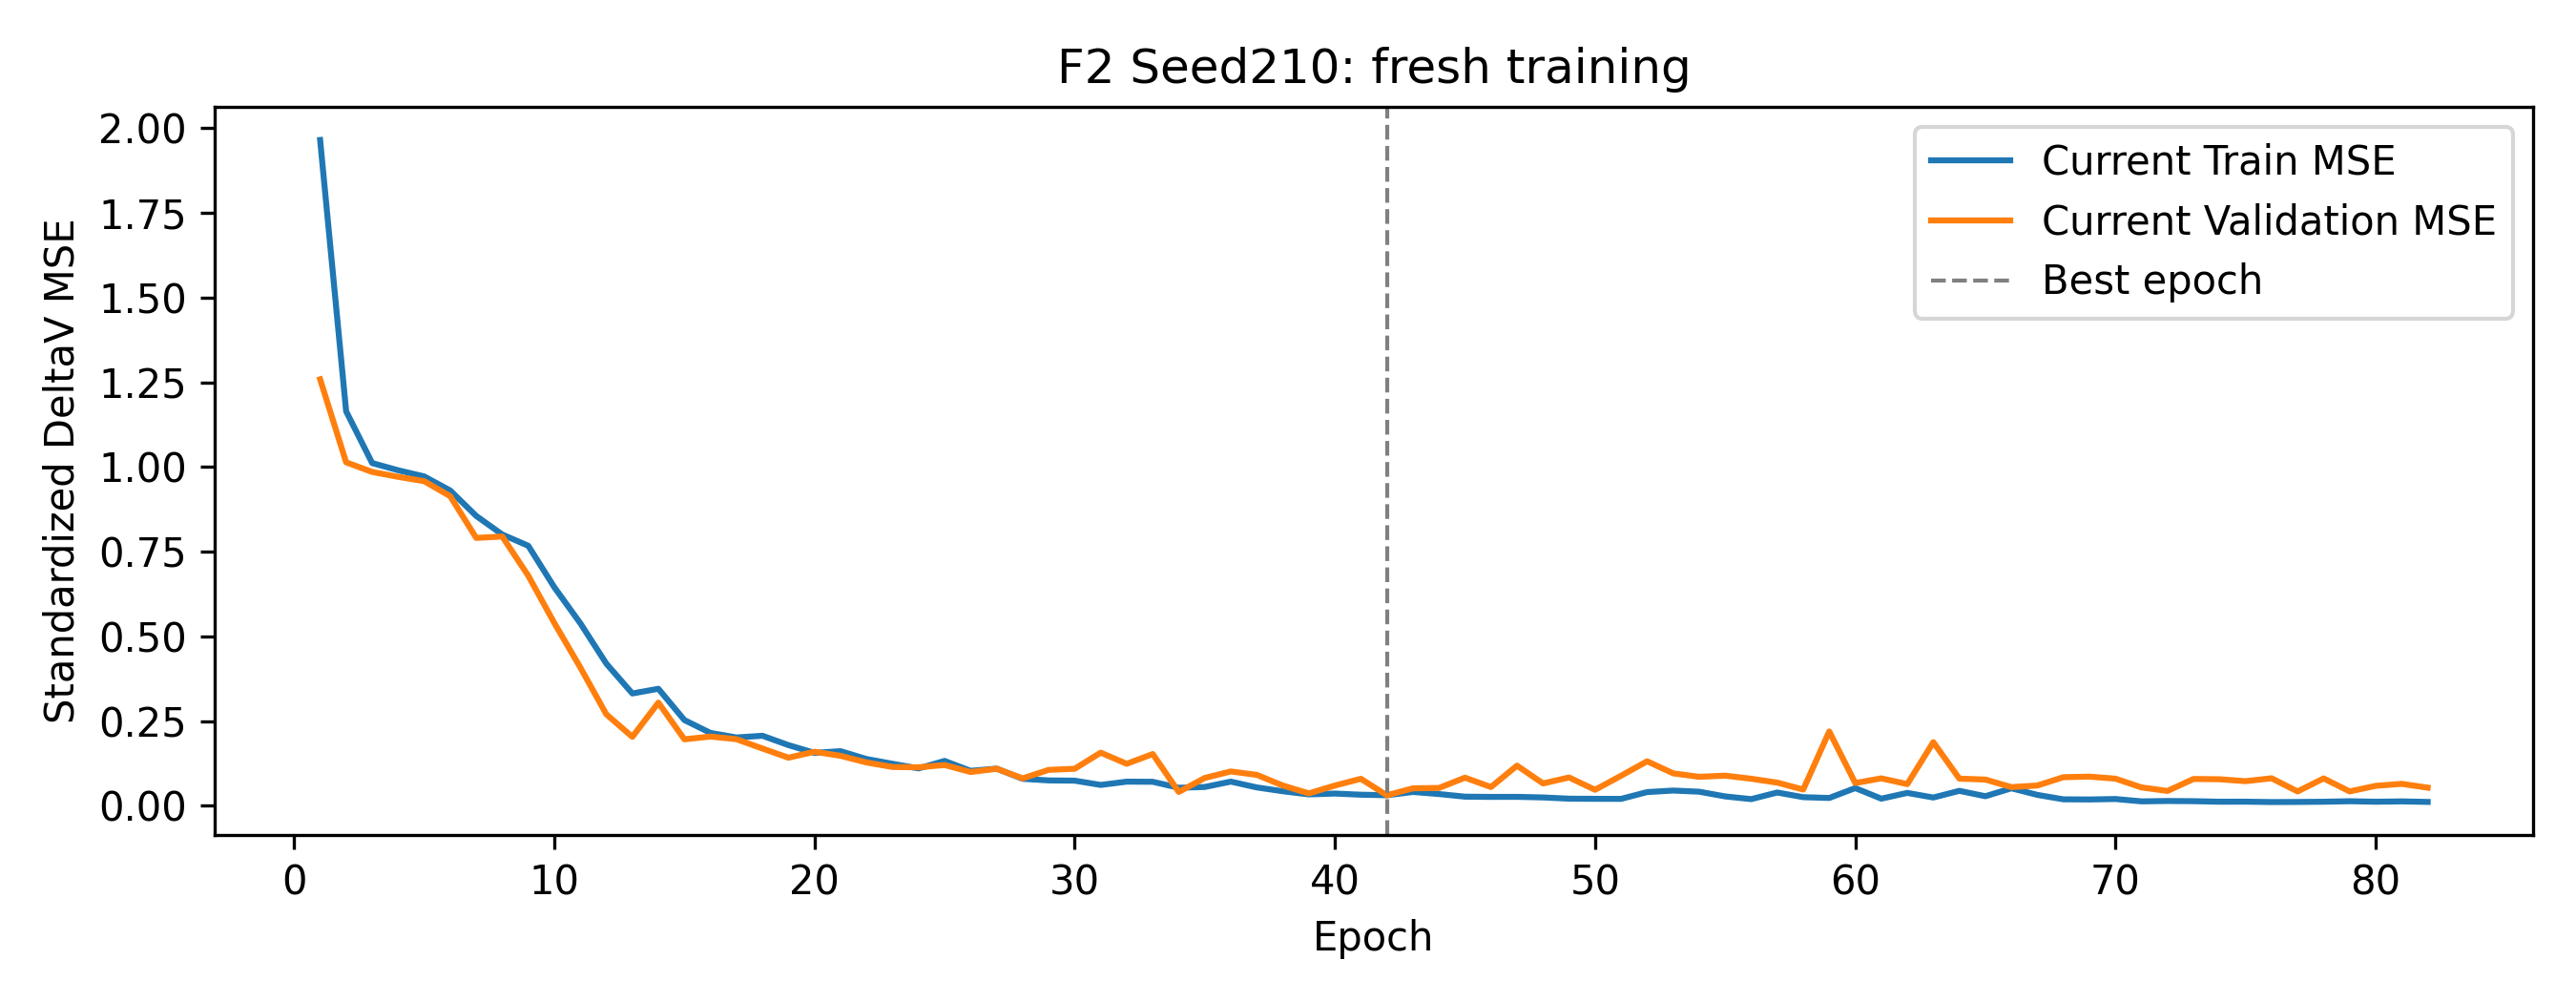

formal F2 Seed 210 | Epoch 2/450 | Train Loss 1.164183 | Validation Loss 1.013581 | Best Epoch 2 | Patience 0/40
formal F2 Seed 210 | Epoch 3/450 | Train Loss 1.011426 | Validation Loss 0.985188 | Best Epoch 3 | Patience 0/40
formal F2 Seed 210 | Epoch 4/450 | Train Loss 0.990082 | Validation Loss 0.970728 | Best Epoch 4 | Patience 0/40
formal F2 Seed 210 | Epoch 5/450 | Train Loss 0.971987 | Validation Loss 0.957969 | Best Epoch 5 | Patience 0/40
formal F2 Seed 210 | Epoch 6/450 | Train Loss 0.930402 | Validation Loss 0.913578 | Best Epoch 6 | Patience 0/40
formal F2 Seed 210 | Epoch 7/450 | Train Loss 0.855288 | Validation Loss 0.790489 | Best Epoch 7 | Patience 0/40
formal F2 Seed 210 | Epoch 8/450 | Train Loss 0.800578 | Validation Loss 0.794627 | Best Epoch 7 | Patience 1/40
formal F2 Seed 210 | Epoch 9/450 | Train Loss 0.767260 | Validation Loss 0.678811 | Best Epoch 9 | Patience 0/40
formal F2 Seed 210 | Epoch 10/450 | Train Loss 0.644936 | Validation Loss 0.539432 | Best Epoch 

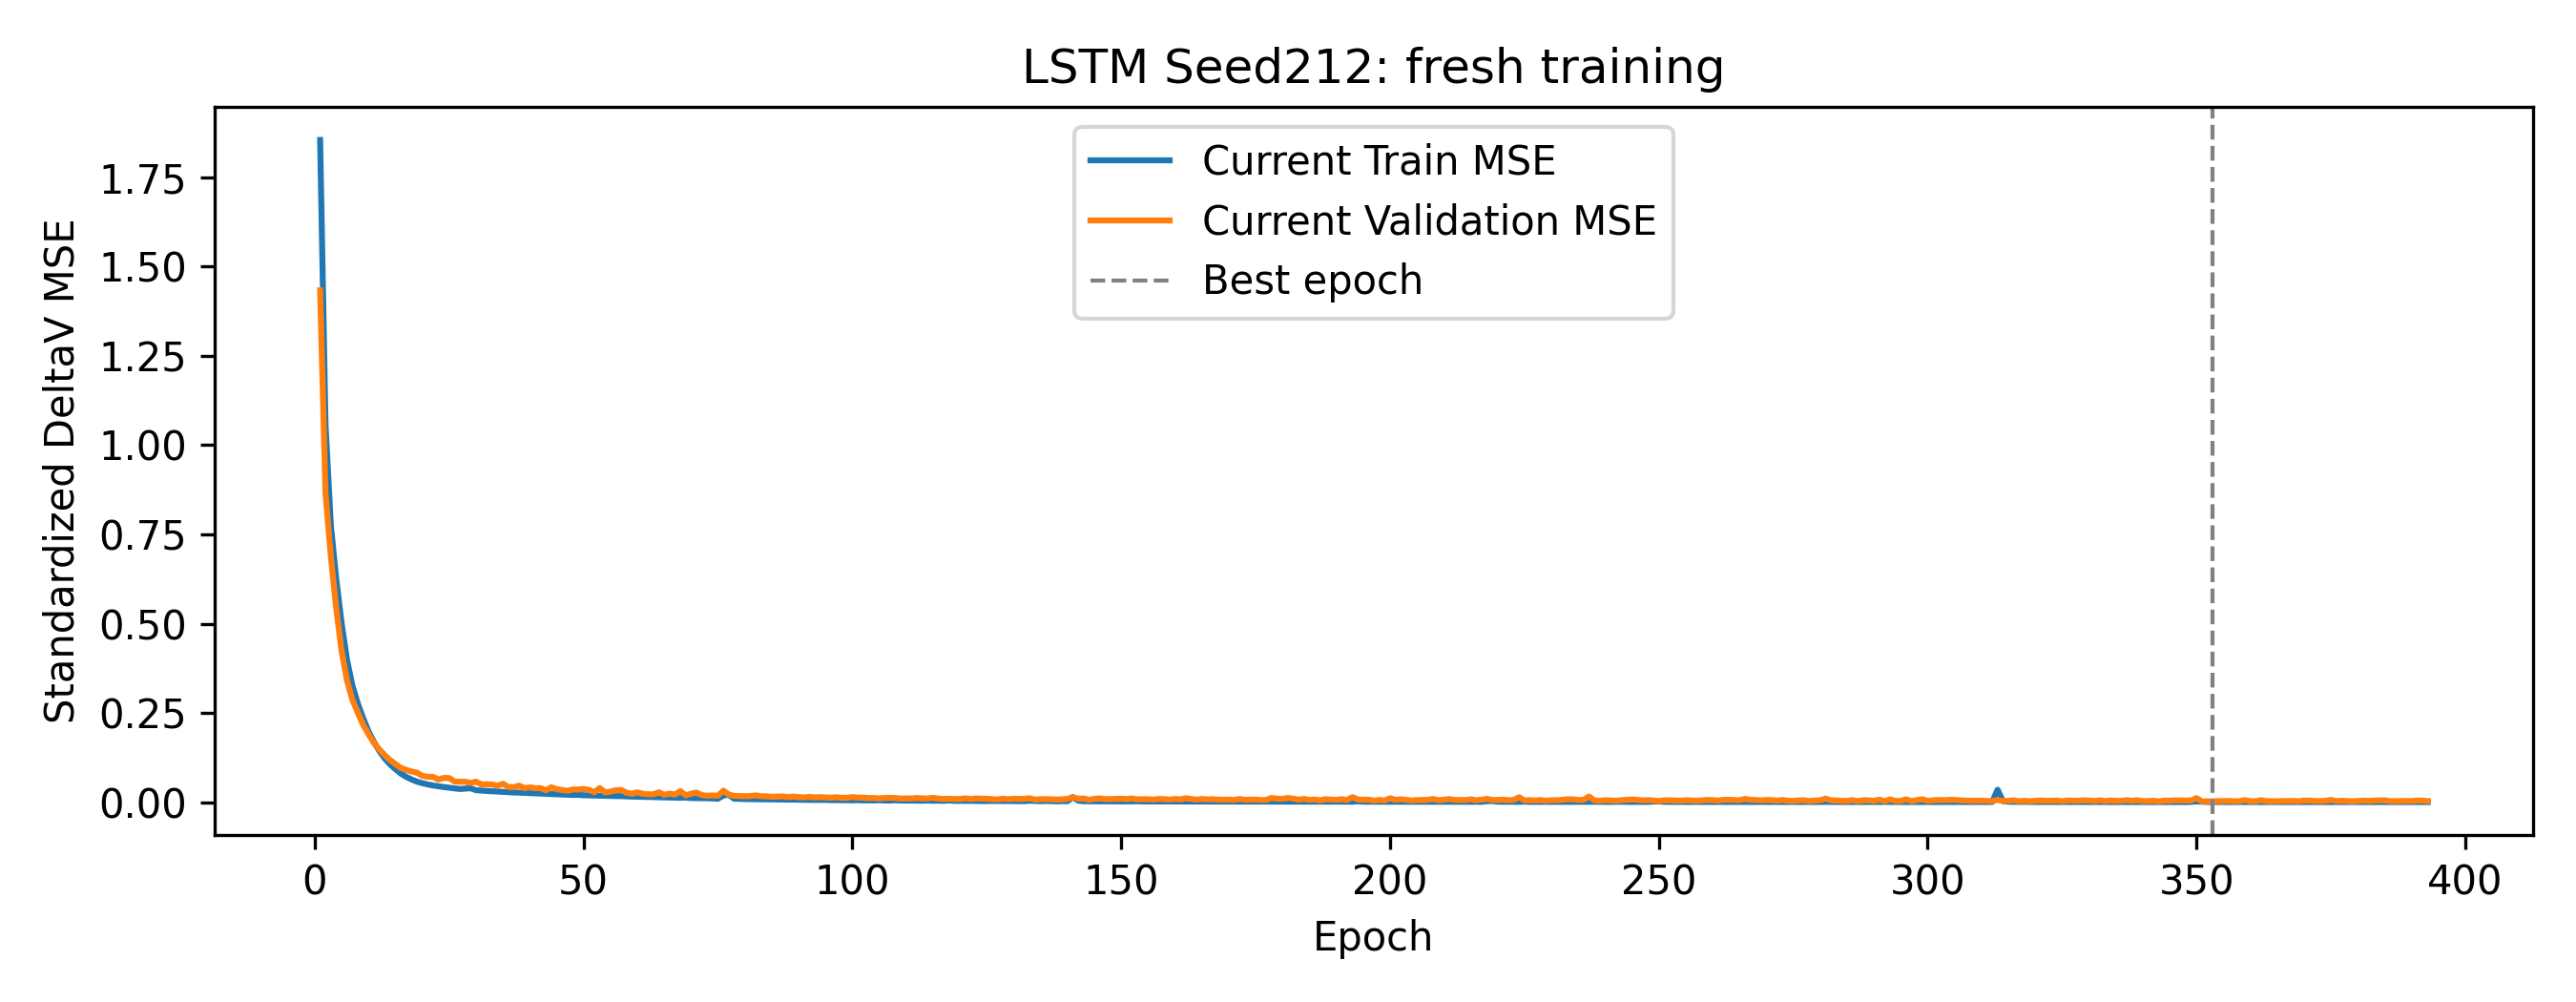

formal LSTM Seed 212 | Epoch 2/450 | Train Loss 1.058236 | Validation Loss 0.865082 | Best Epoch 2 | Patience 0/40
formal LSTM Seed 212 | Epoch 3/450 | Train Loss 0.774060 | Validation Loss 0.687005 | Best Epoch 3 | Patience 0/40
formal LSTM Seed 212 | Epoch 4/450 | Train Loss 0.624907 | Validation Loss 0.542275 | Best Epoch 4 | Patience 0/40
formal LSTM Seed 212 | Epoch 5/450 | Train Loss 0.500986 | Validation Loss 0.422762 | Best Epoch 5 | Patience 0/40
formal LSTM Seed 212 | Epoch 6/450 | Train Loss 0.398933 | Validation Loss 0.340582 | Best Epoch 6 | Patience 0/40
formal LSTM Seed 212 | Epoch 7/450 | Train Loss 0.326827 | Validation Loss 0.287169 | Best Epoch 7 | Patience 0/40
formal LSTM Seed 212 | Epoch 8/450 | Train Loss 0.276763 | Validation Loss 0.251113 | Best Epoch 8 | Patience 0/40
formal LSTM Seed 212 | Epoch 9/450 | Train Loss 0.235541 | Validation Loss 0.216835 | Best Epoch 9 | Patience 0/40
formal LSTM Seed 212 | Epoch 10/450 | Train Loss 0.198437 | Validation Loss 0.19

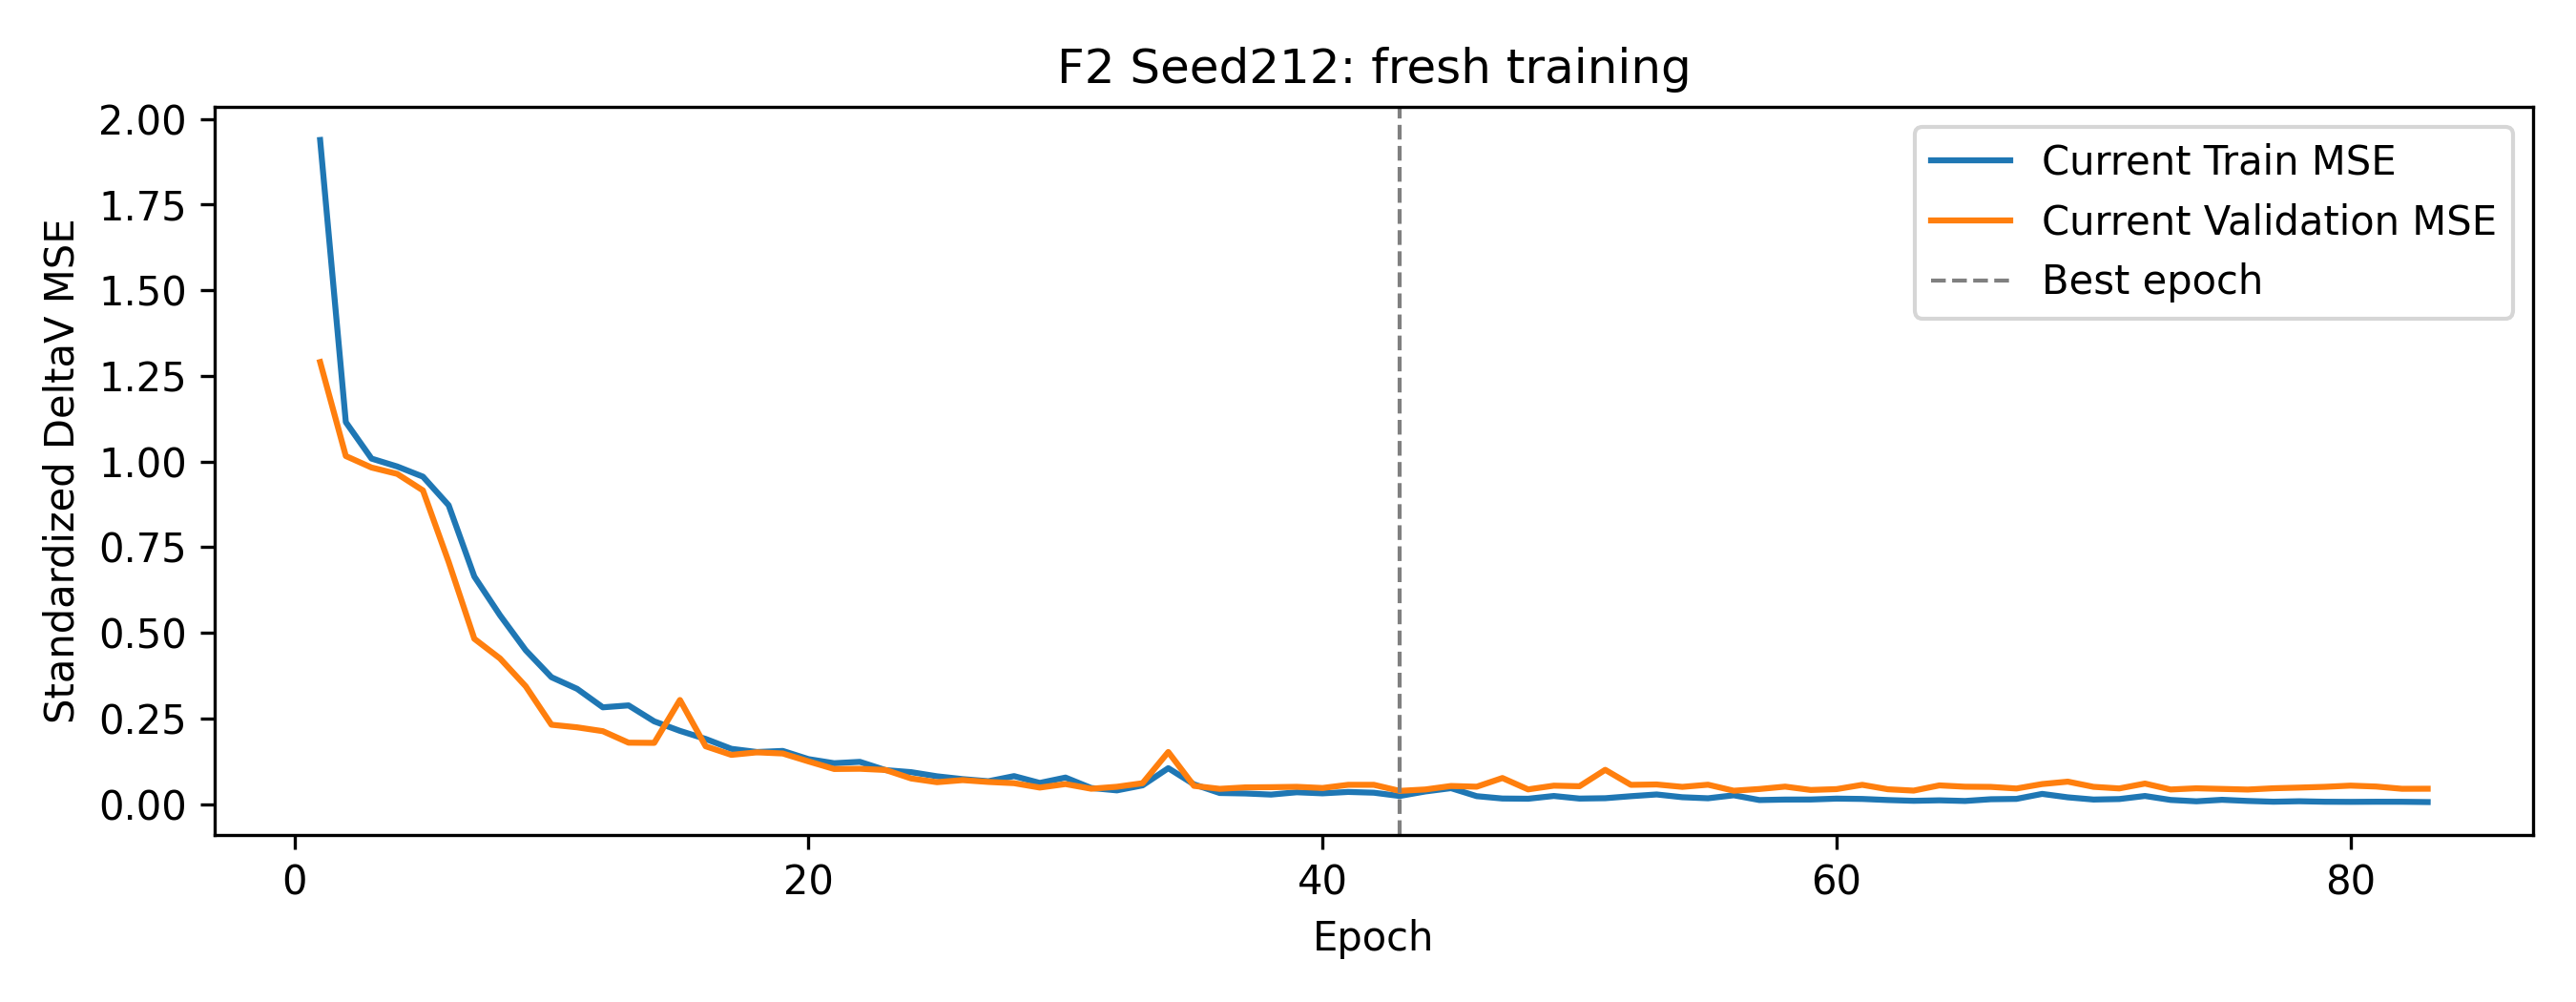

formal F2 Seed 212 | Epoch 2/450 | Train Loss 1.115049 | Validation Loss 1.016072 | Best Epoch 2 | Patience 0/40
formal F2 Seed 212 | Epoch 3/450 | Train Loss 1.008615 | Validation Loss 0.982550 | Best Epoch 3 | Patience 0/40
formal F2 Seed 212 | Epoch 4/450 | Train Loss 0.985568 | Validation Loss 0.963974 | Best Epoch 4 | Patience 0/40
formal F2 Seed 212 | Epoch 5/450 | Train Loss 0.955910 | Validation Loss 0.915758 | Best Epoch 5 | Patience 0/40
formal F2 Seed 212 | Epoch 6/450 | Train Loss 0.872538 | Validation Loss 0.707121 | Best Epoch 6 | Patience 0/40
formal F2 Seed 212 | Epoch 7/450 | Train Loss 0.664266 | Validation Loss 0.482515 | Best Epoch 7 | Patience 0/40
formal F2 Seed 212 | Epoch 8/450 | Train Loss 0.551037 | Validation Loss 0.425038 | Best Epoch 8 | Patience 0/40
formal F2 Seed 212 | Epoch 9/450 | Train Loss 0.448991 | Validation Loss 0.343707 | Best Epoch 9 | Patience 0/40
formal F2 Seed 212 | Epoch 10/450 | Train Loss 0.370385 | Validation Loss 0.231586 | Best Epoch 

In [4]:
ledgers=formal_train(run,windows,scaler,prepared,protocol)

In [5]:
table,means,paired=formal_evaluate(run,frame,windows,scaler,prepared,ledgers)

New inference LSTM Seed 42: TRAIN, 1750 windows
New inference LSTM Seed 42: VALIDATION, 218 windows
New inference LSTM Seed 42: TEST, 527 windows
New inference F2 Seed 42: TRAIN, 1750 windows
New inference F2 Seed 42: VALIDATION, 218 windows
New inference F2 Seed 42: TEST, 527 windows
New inference LSTM Seed 103: TRAIN, 1750 windows
New inference LSTM Seed 103: VALIDATION, 218 windows
New inference LSTM Seed 103: TEST, 527 windows
New inference F2 Seed 103: TRAIN, 1750 windows
New inference F2 Seed 103: VALIDATION, 218 windows
New inference F2 Seed 103: TEST, 527 windows
New inference LSTM Seed 193: TRAIN, 1750 windows
New inference LSTM Seed 193: VALIDATION, 218 windows
New inference LSTM Seed 193: TEST, 527 windows
New inference F2 Seed 193: TRAIN, 1750 windows
New inference F2 Seed 193: VALIDATION, 218 windows
New inference F2 Seed 193: TEST, 527 windows
New inference LSTM Seed 202: TRAIN, 1750 windows
New inference LSTM Seed 202: VALIDATION, 218 windows
New inference LSTM Seed 202:

,model,seed,partition,RMSE_mV,MAE_mV,R2,queries,origins,unique_targets
2,LSTM,42,TEST,25.060866,5.804616,0.983299,12648,527,619
5,F2,42,TEST,41.455588,11.224501,0.954299,12648,527,619
8,LSTM,103,TEST,24.926502,5.547002,0.983477,12648,527,619
11,F2,103,TEST,44.309040,11.600653,0.947792,12648,527,619
14,LSTM,193,TEST,24.767142,4.810536,0.983688,12648,527,619
17,F2,193,TEST,48.398668,13.547583,0.937709,12648,527,619
20,LSTM,202,TEST,24.594026,5.005282,0.983915,12648,527,619
23,F2,202,TEST,43.510554,7.994754,0.949656,12648,527,619
26,LSTM,210,TEST,25.301401,6.686179,0.982977,12648,527,619
29,F2,210,TEST,46.263481,16.154000,0.943084,12648,527,619


,model,n,RMSE_mV_mean,MAE_mV_mean,R2_mean,RMSE_mV_sample_sd,MAE_mV_sample_sd,R2_sample_sd
0,F2,6,44.220508,12.469543,0.947832,2.750398,2.842581,0.006542
1,LSTM,6,24.885444,5.469488,0.983530,0.266084,0.707753,0.000353


,seed,LSTM_RMSE_mV,LSTM_MAE_mV,LSTM_R2,F2_RMSE_mV,F2_MAE_mV,F2_R2,RMSE_mV_F2_minus_LSTM,MAE_mV_F2_minus_LSTM,R2_F2_minus_LSTM
0,42,25.060866,5.804616,0.983299,41.455588,11.224501,0.954299,16.394722,5.419884,-0.028999
1,103,24.926502,5.547002,0.983477,44.309040,11.600653,0.947792,19.382538,6.053651,-0.035686
2,193,24.767142,4.810536,0.983688,48.398668,13.547583,0.937709,23.631525,8.737047,-0.045979
3,202,24.594026,5.005282,0.983915,43.510554,7.994754,0.949656,18.916528,2.989472,-0.034259
4,210,25.301401,6.686179,0.982977,46.263481,16.154000,0.943084,20.962080,9.467821,-0.039892
5,212,24.662724,4.963313,0.983825,41.385717,14.295771,0.954453,16.722993,9.332458,-0.029372


P3: real comparison figures and complete error tables


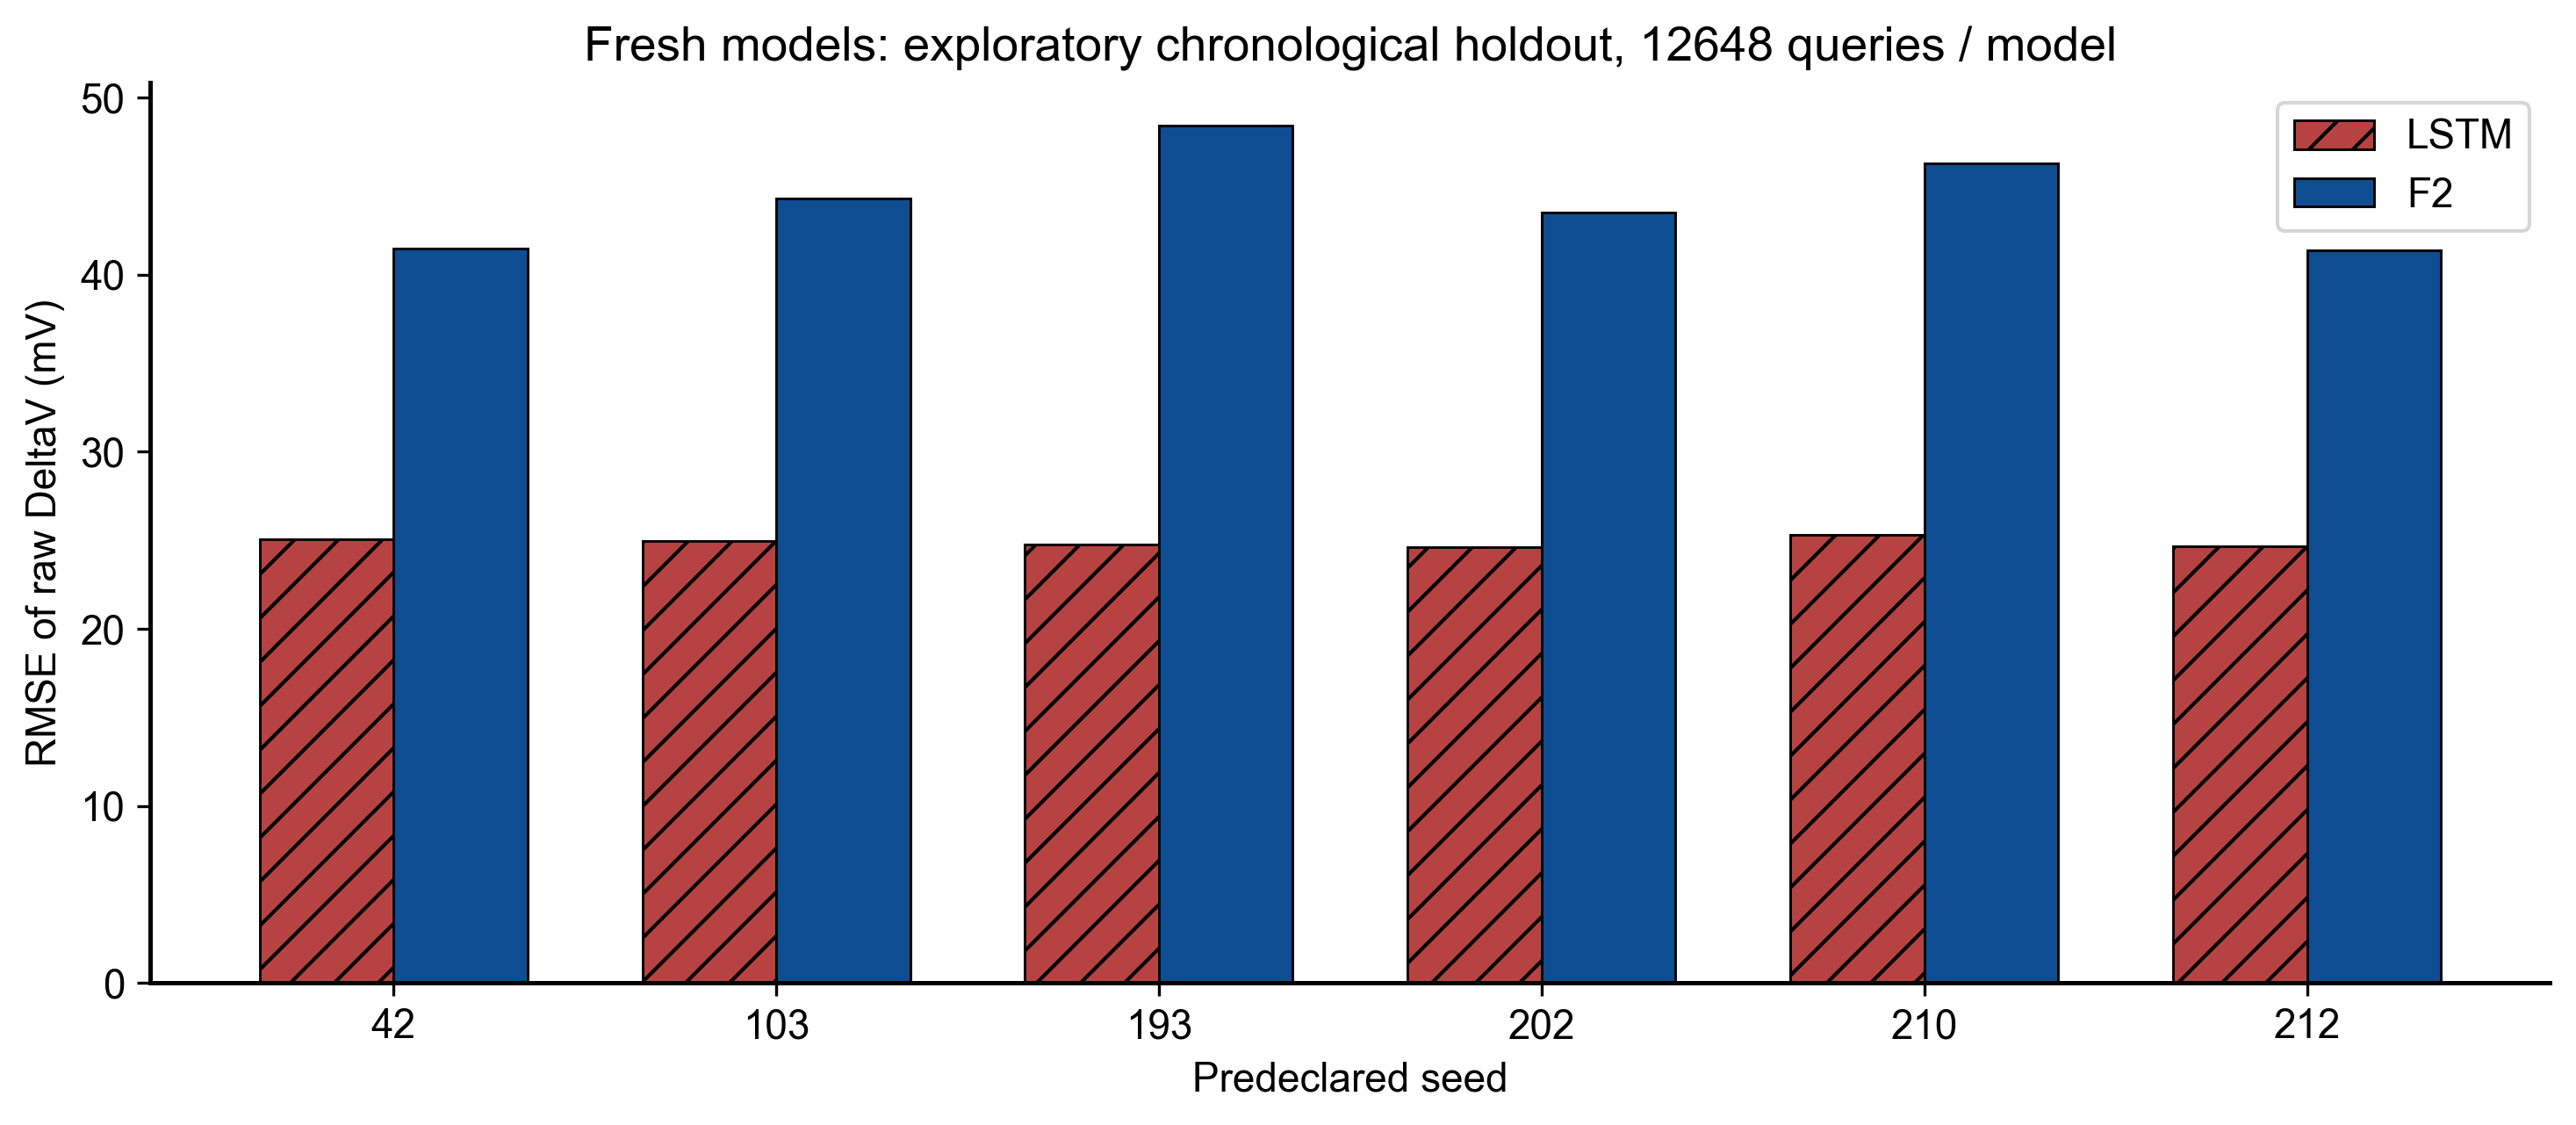

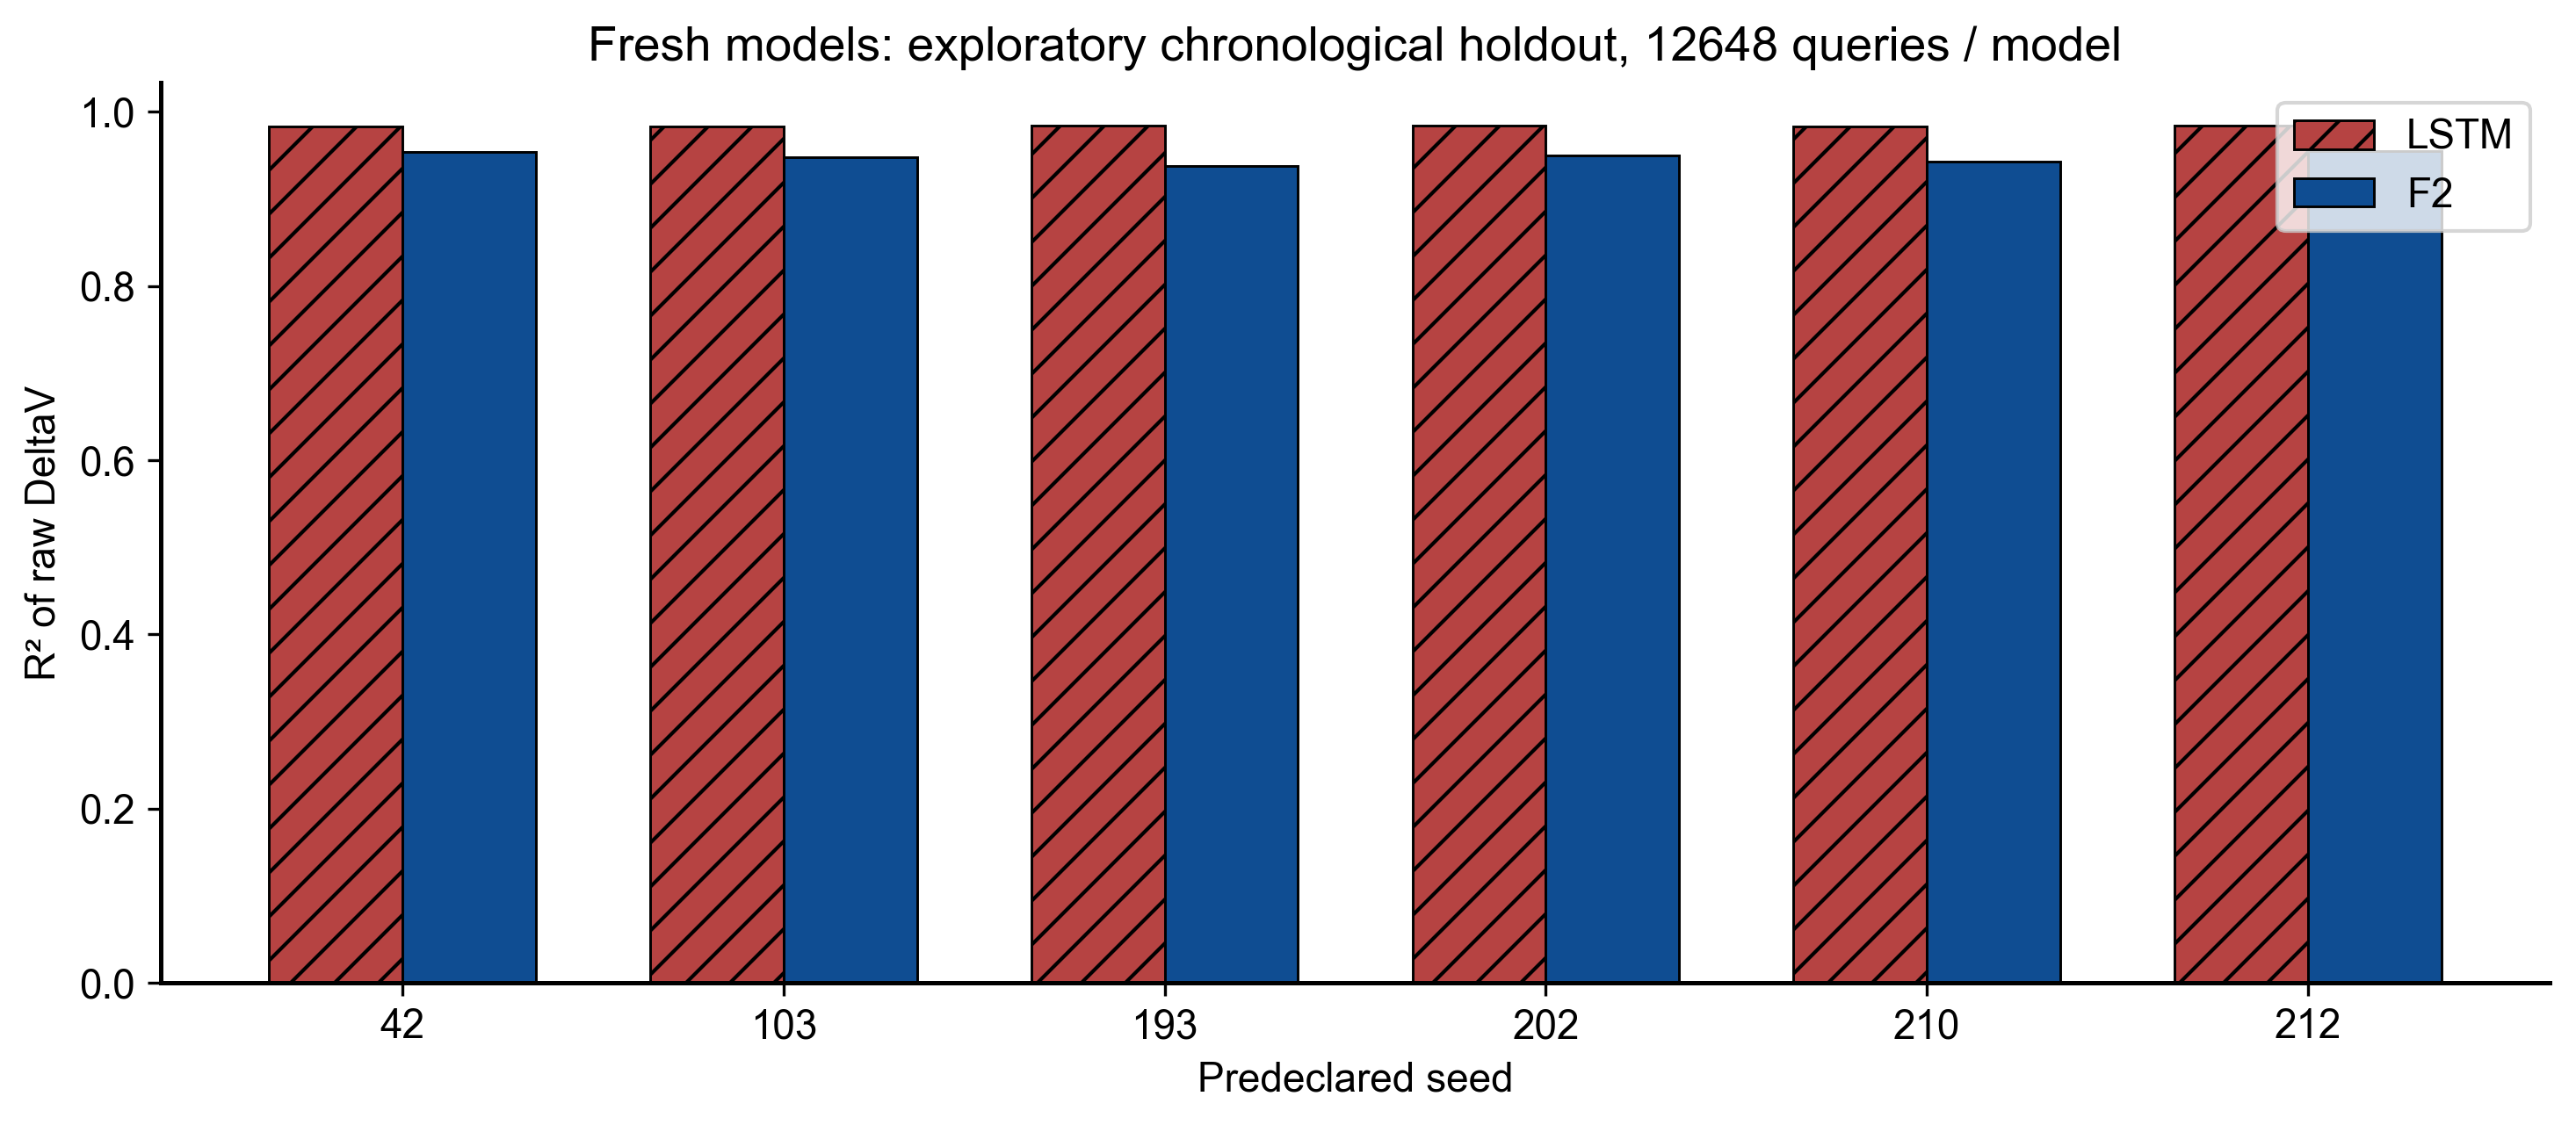

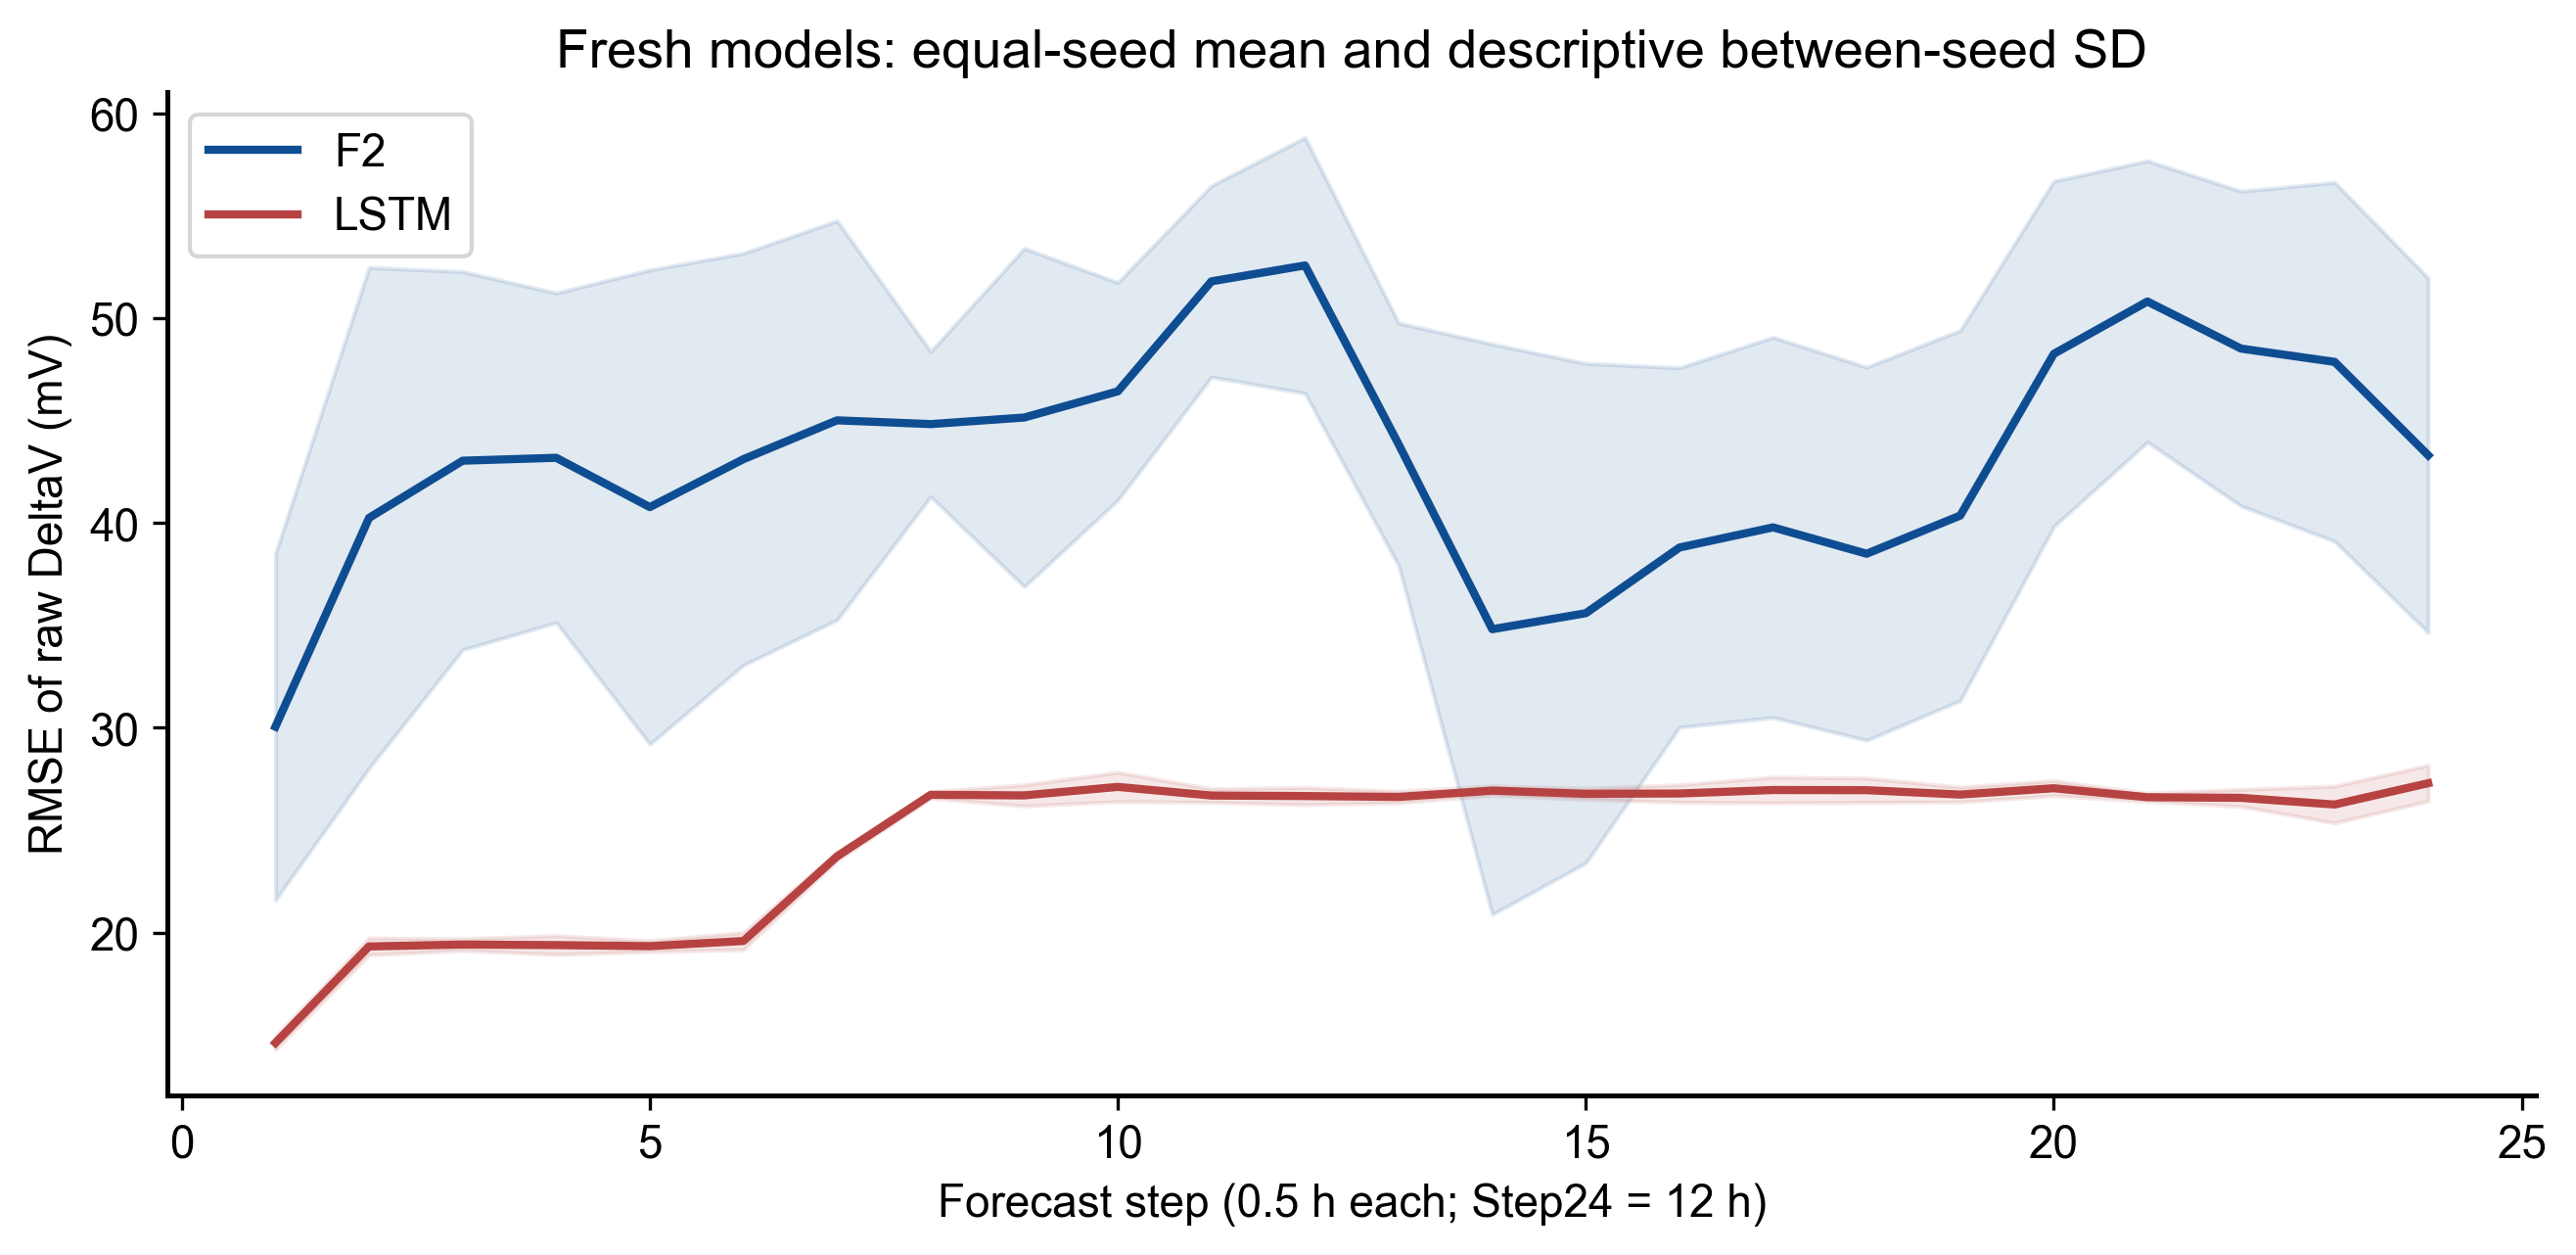

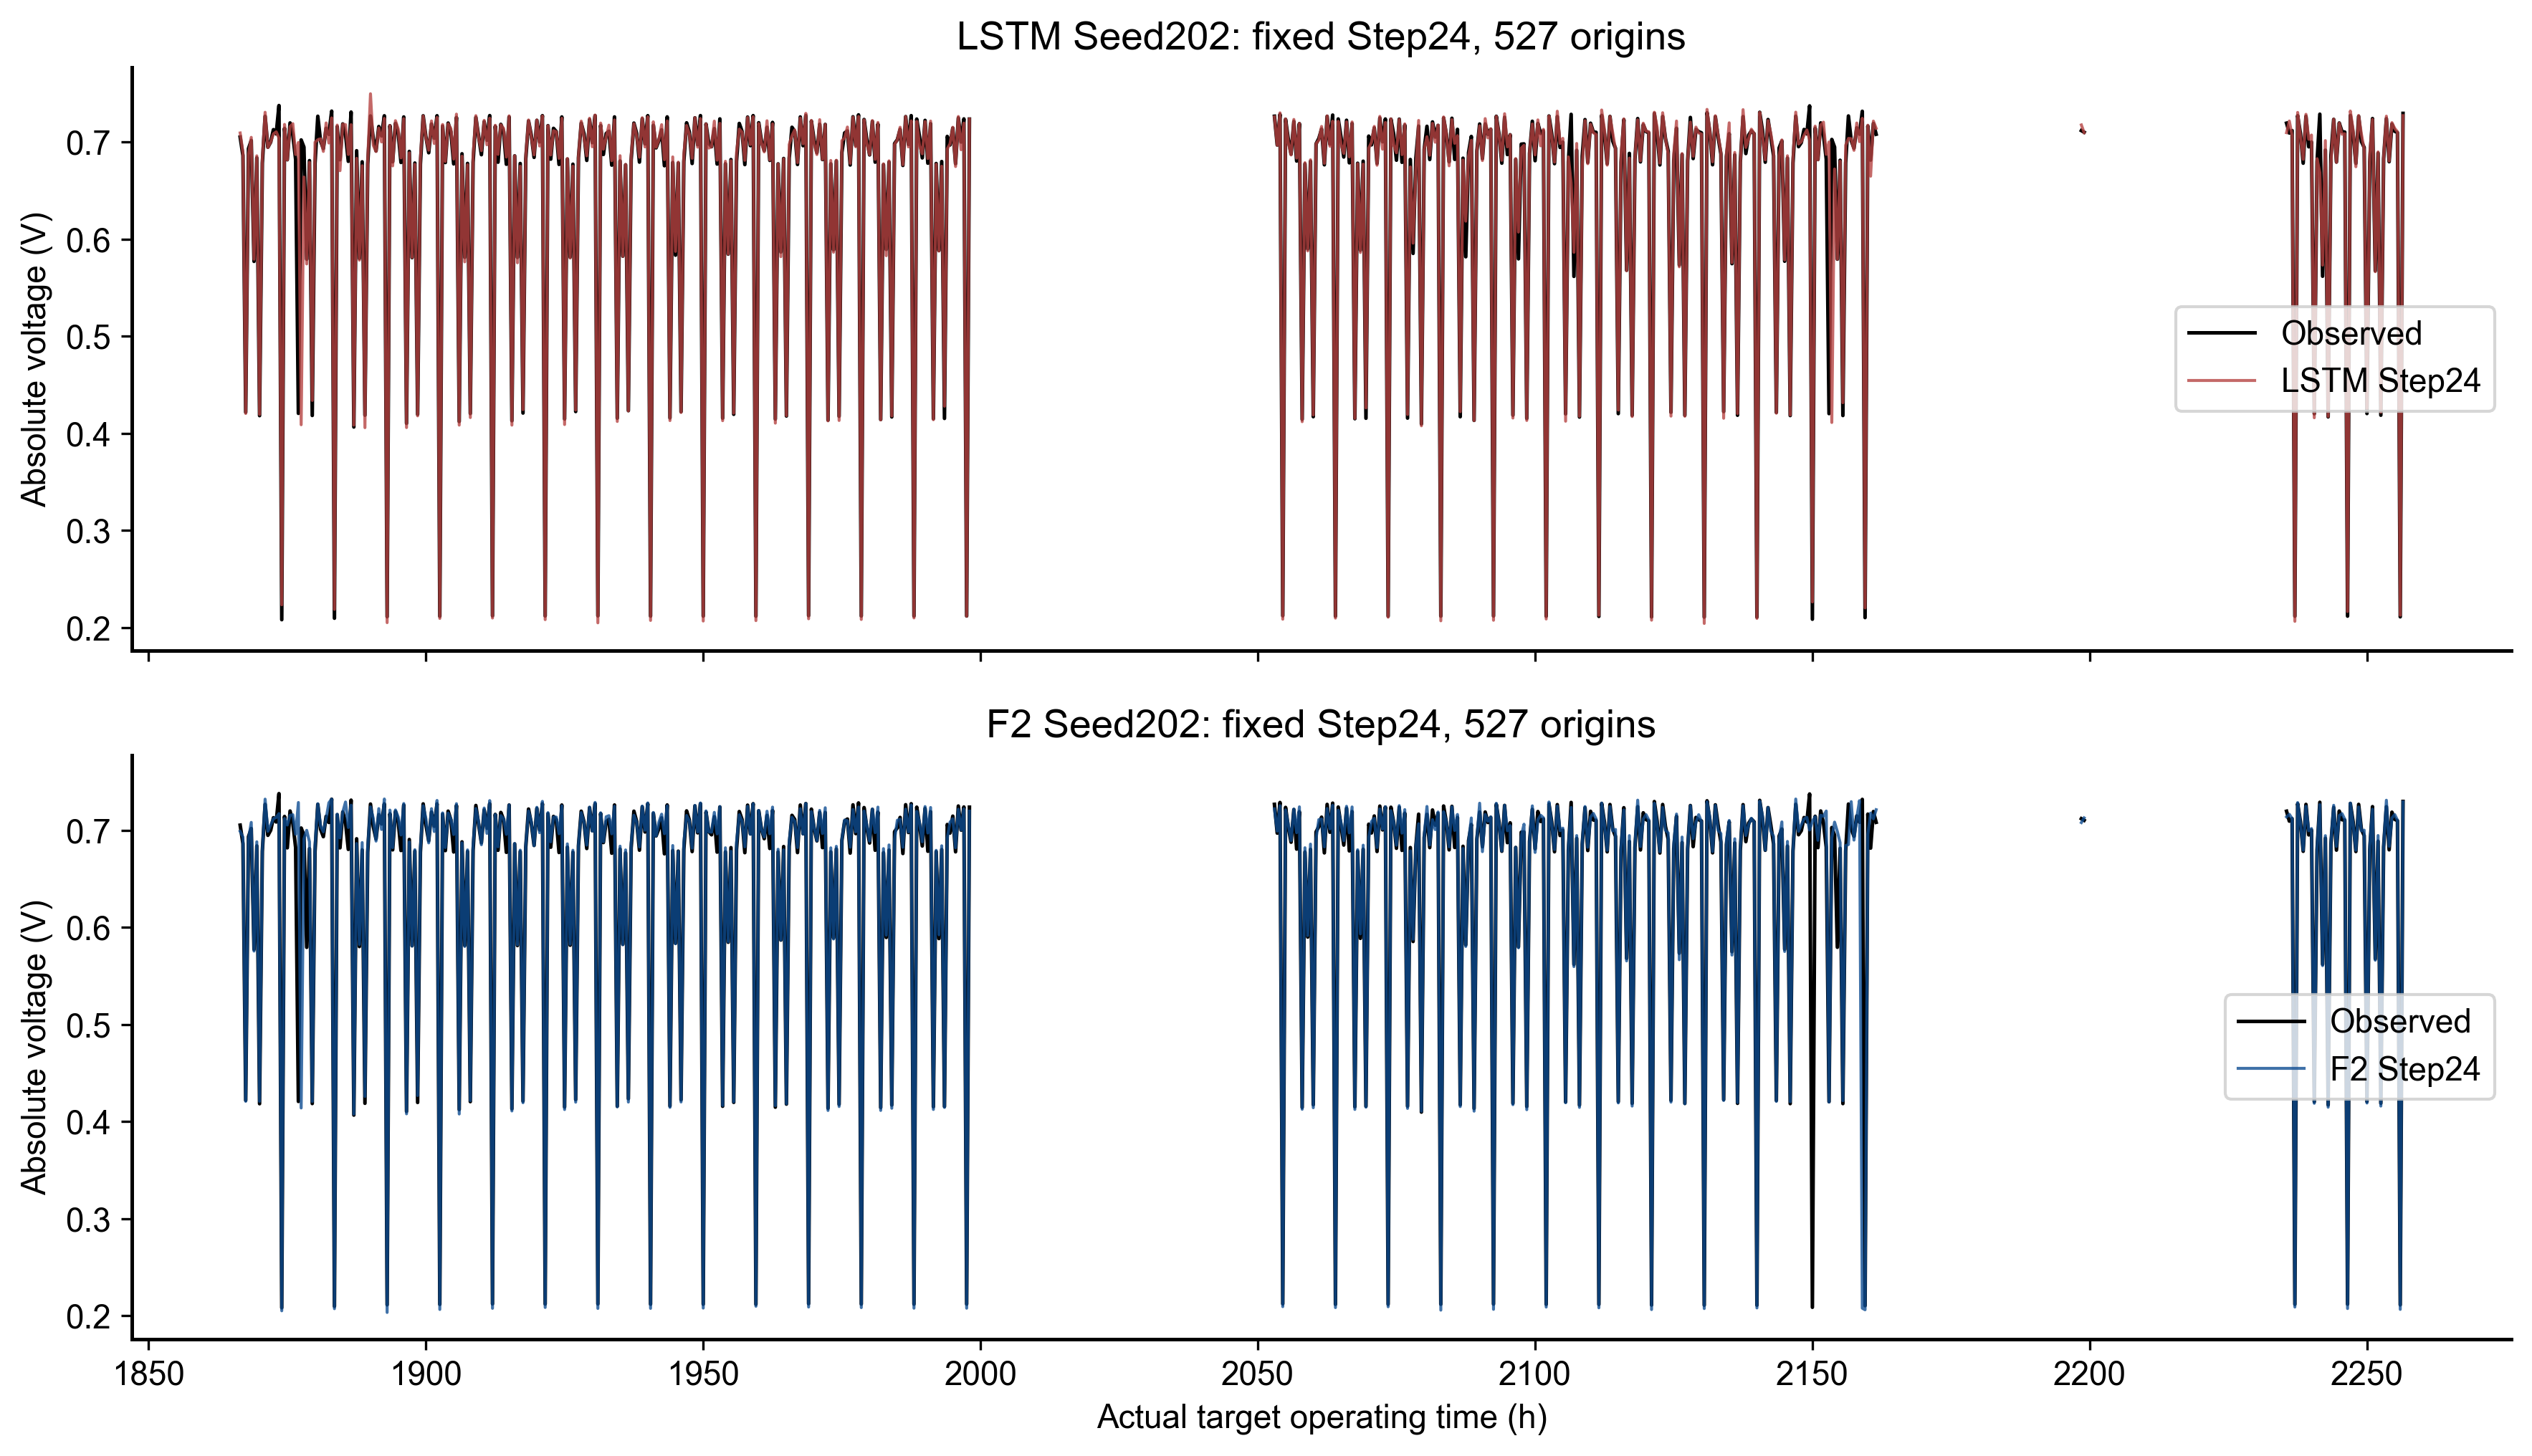

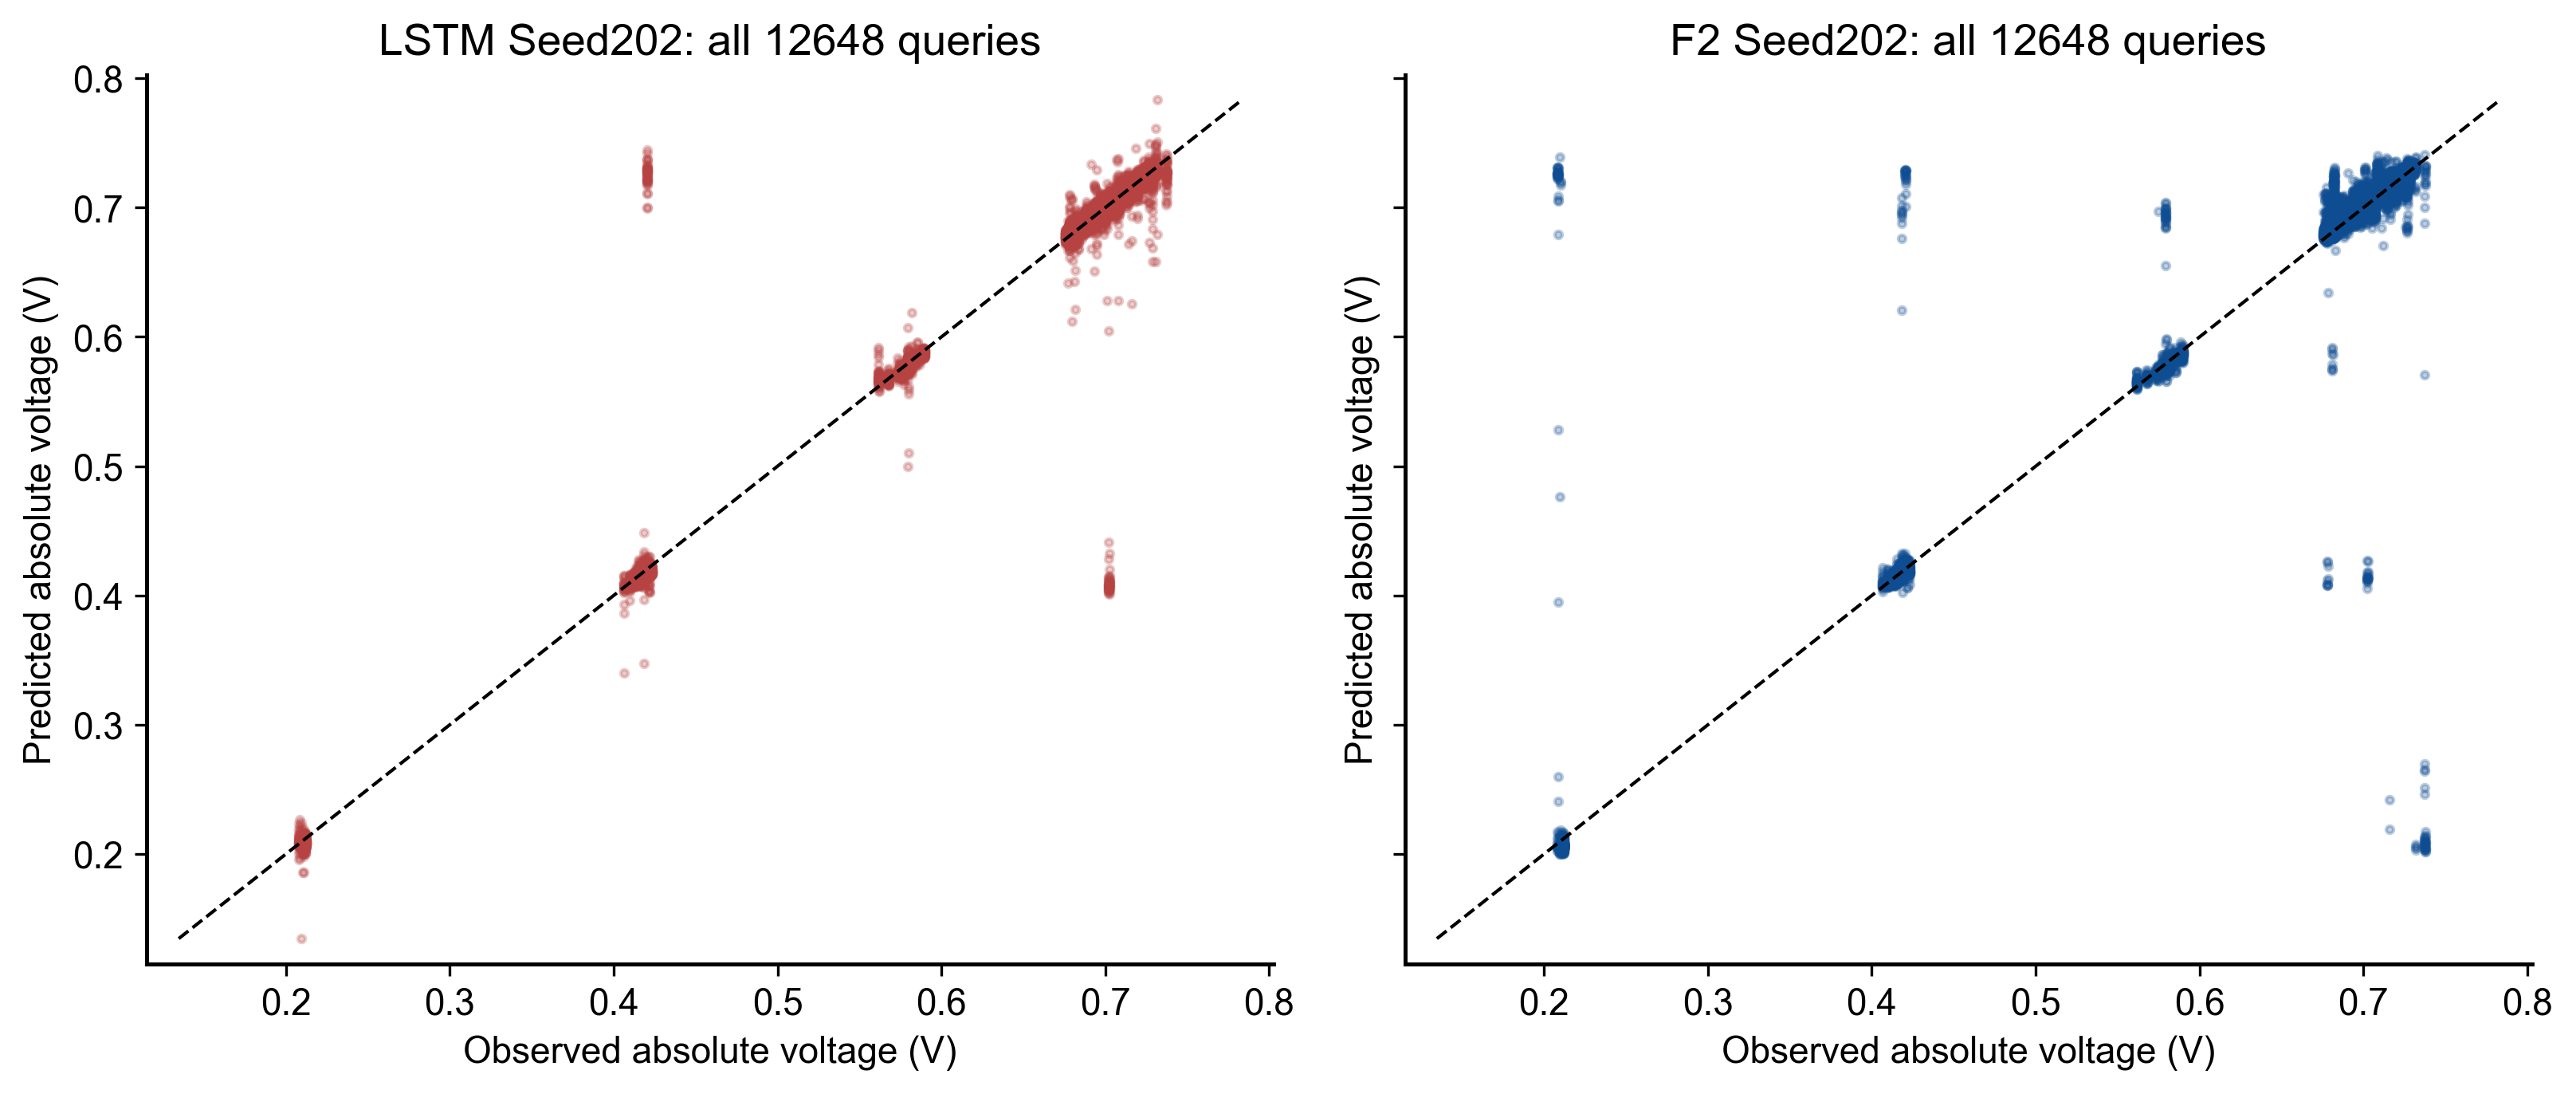

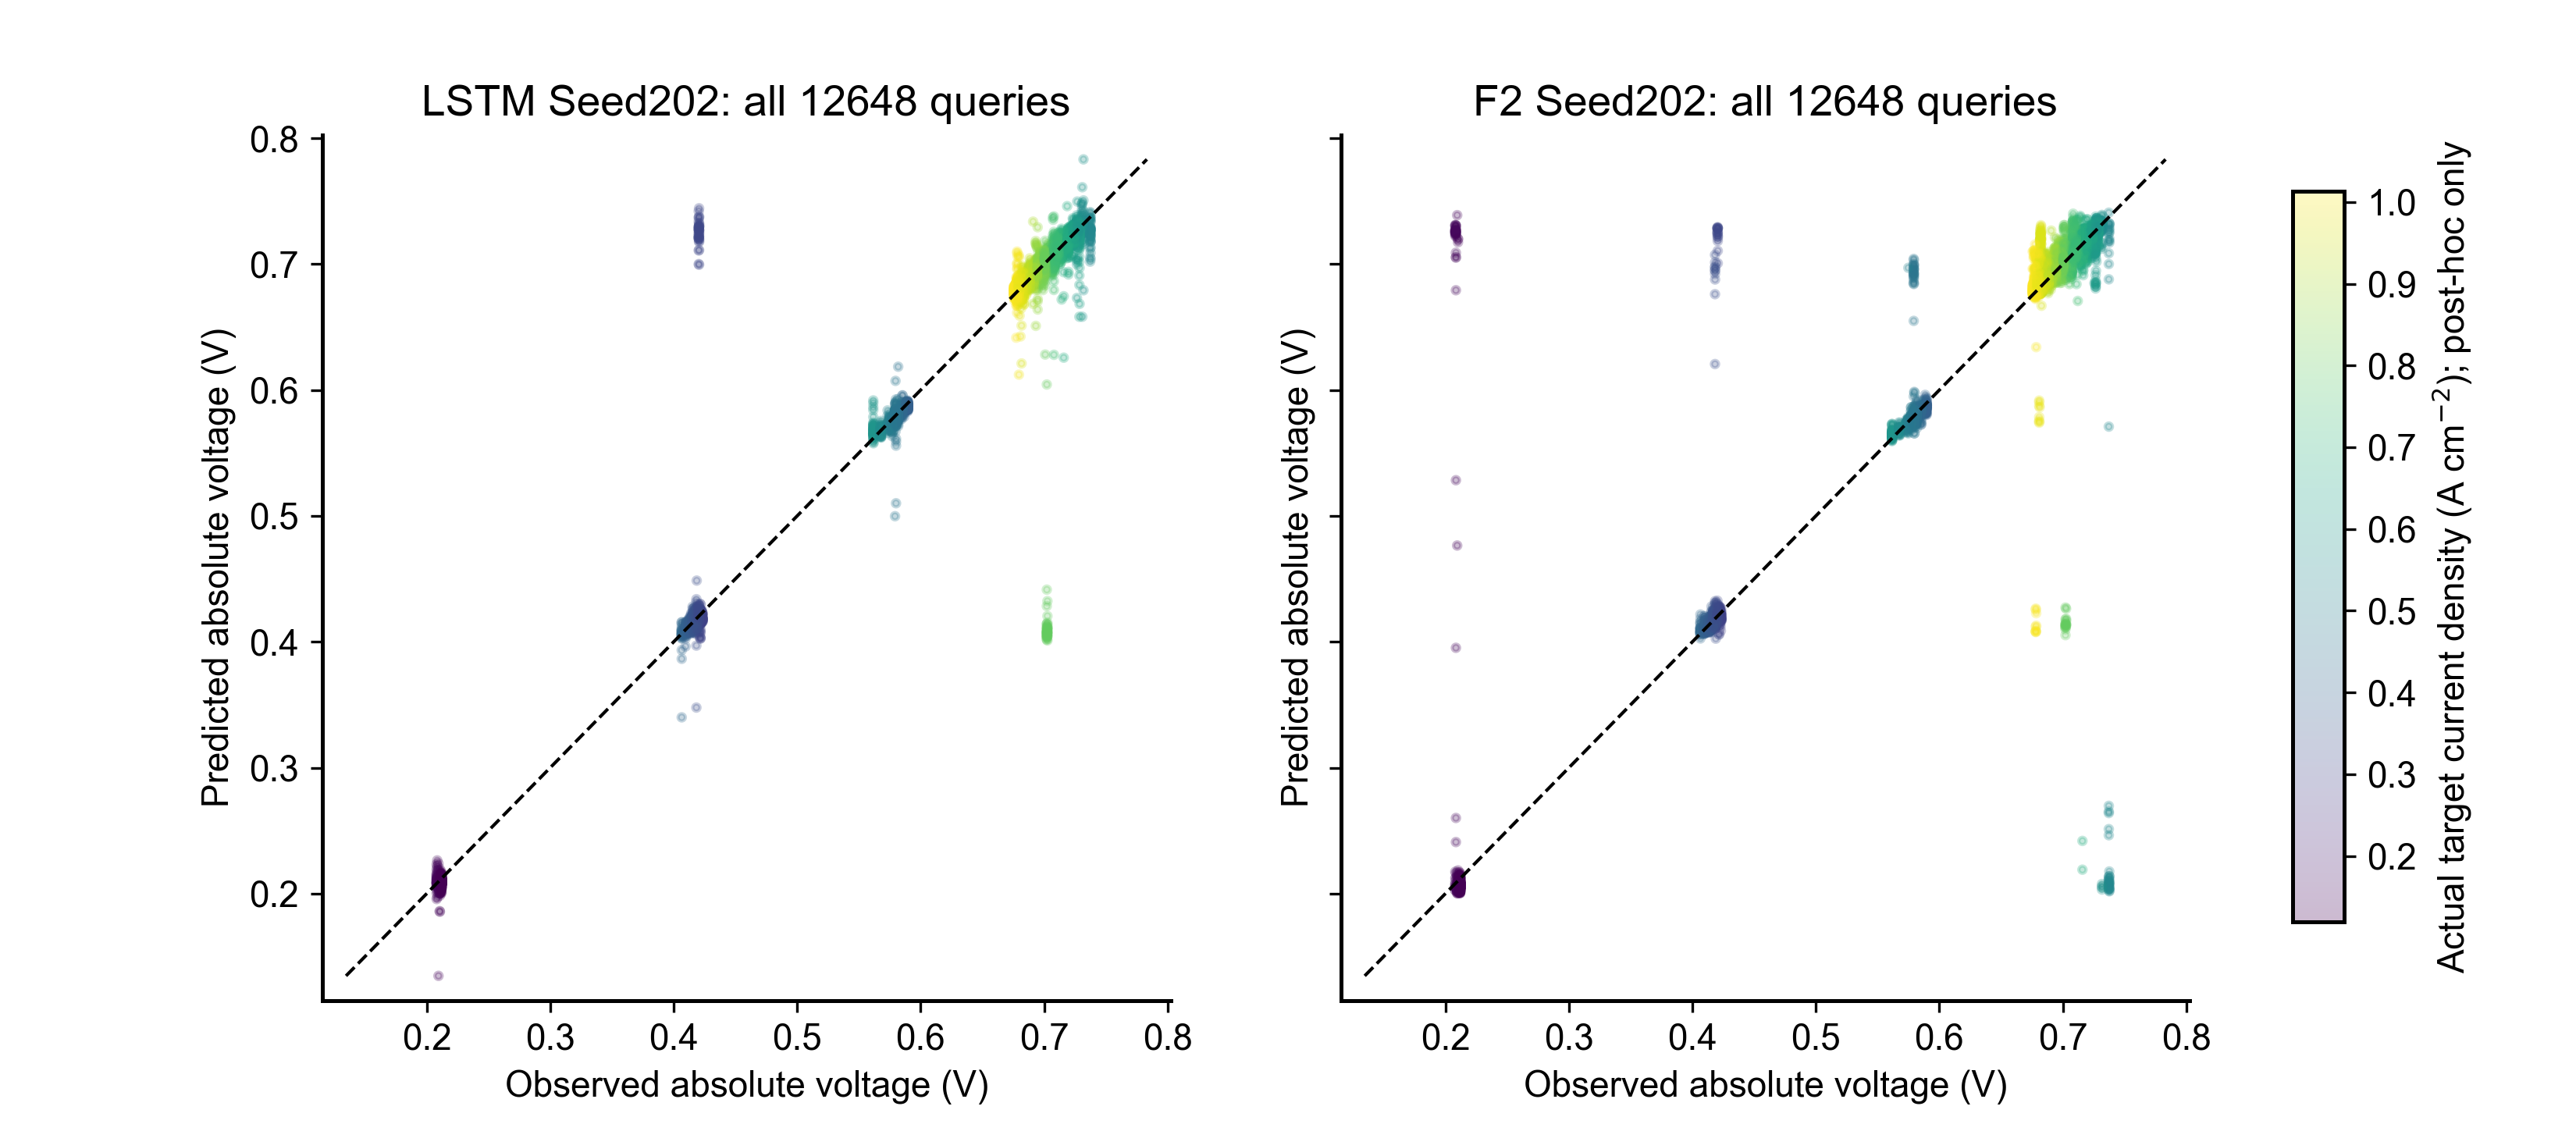

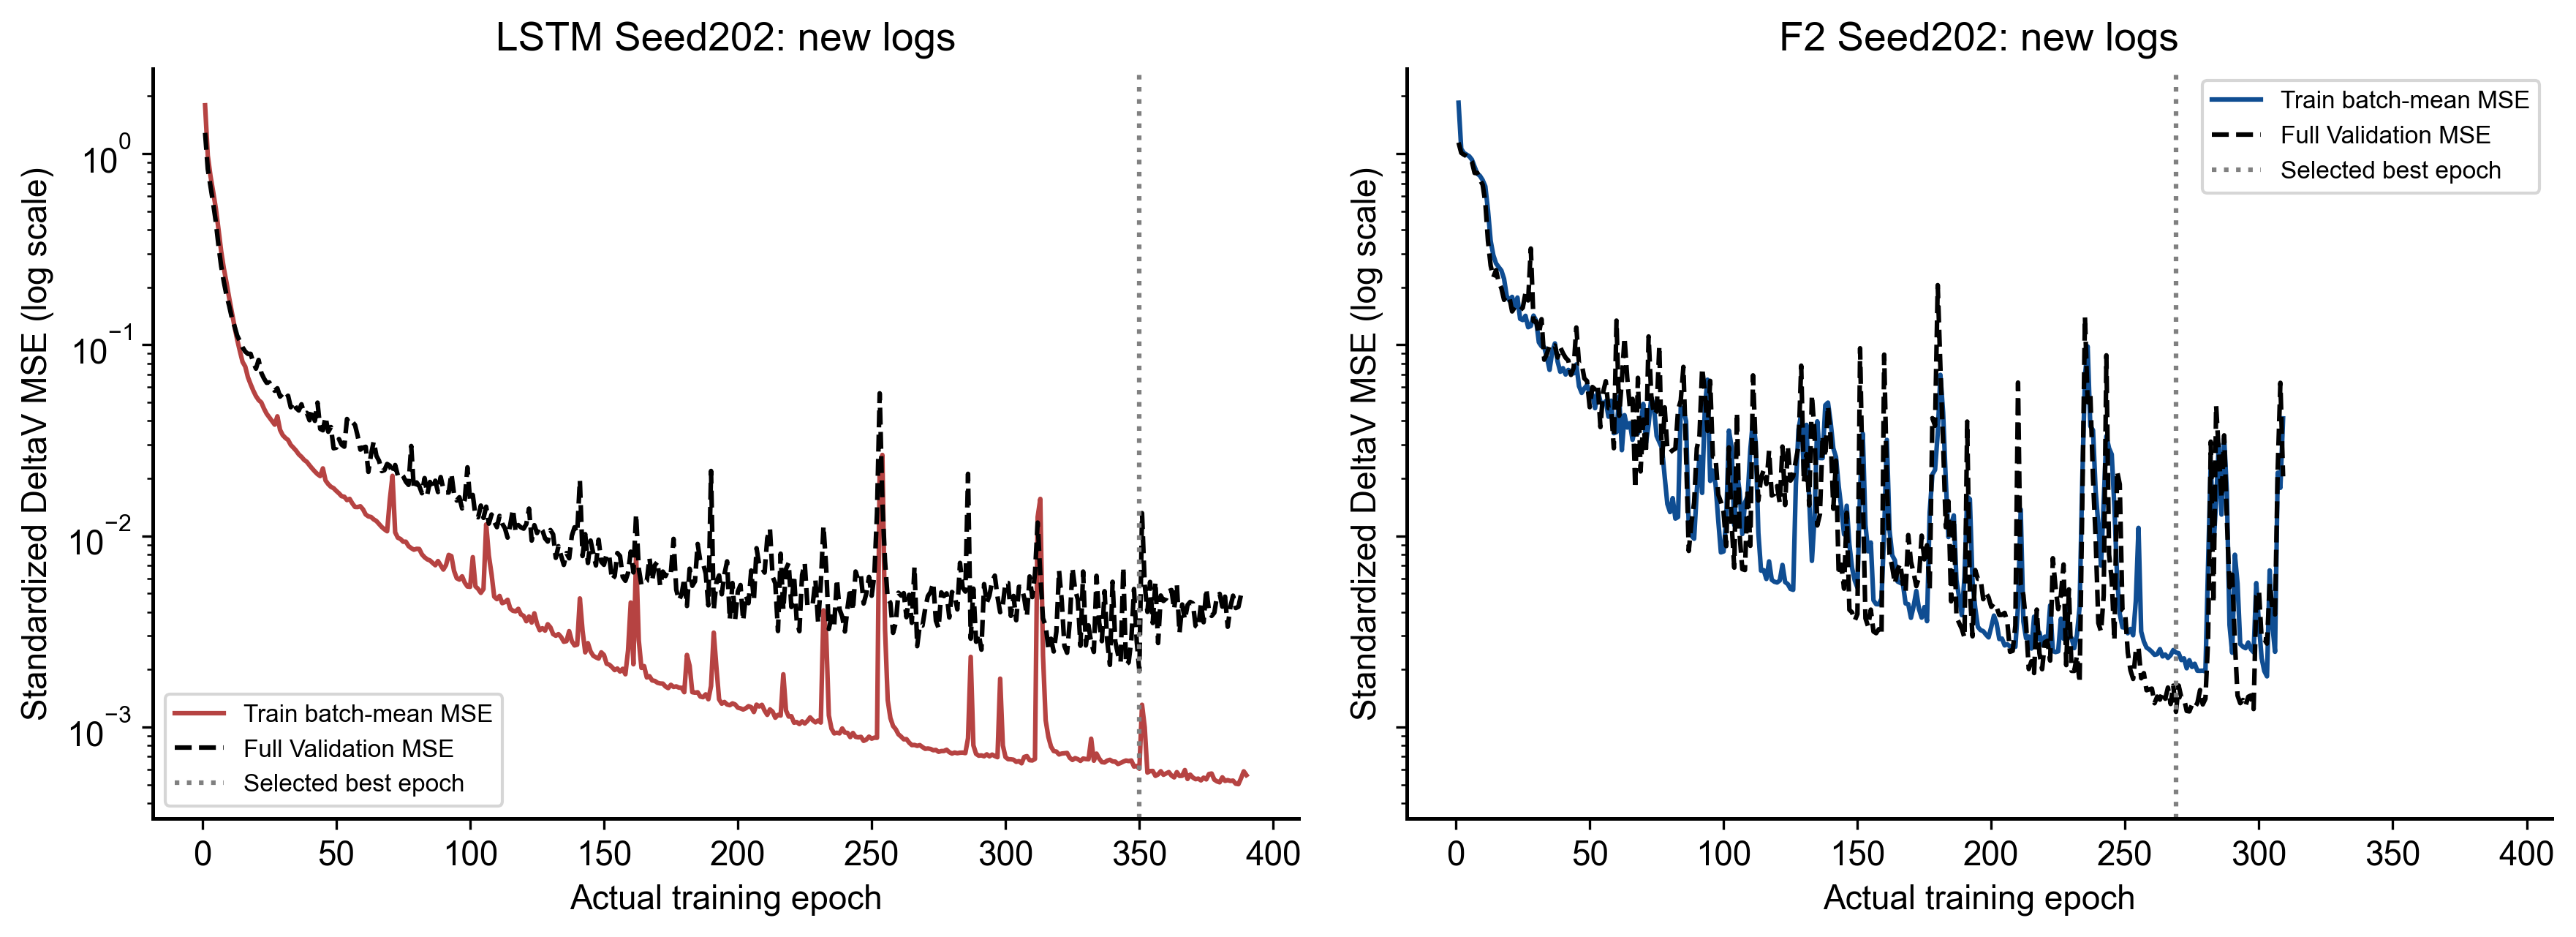

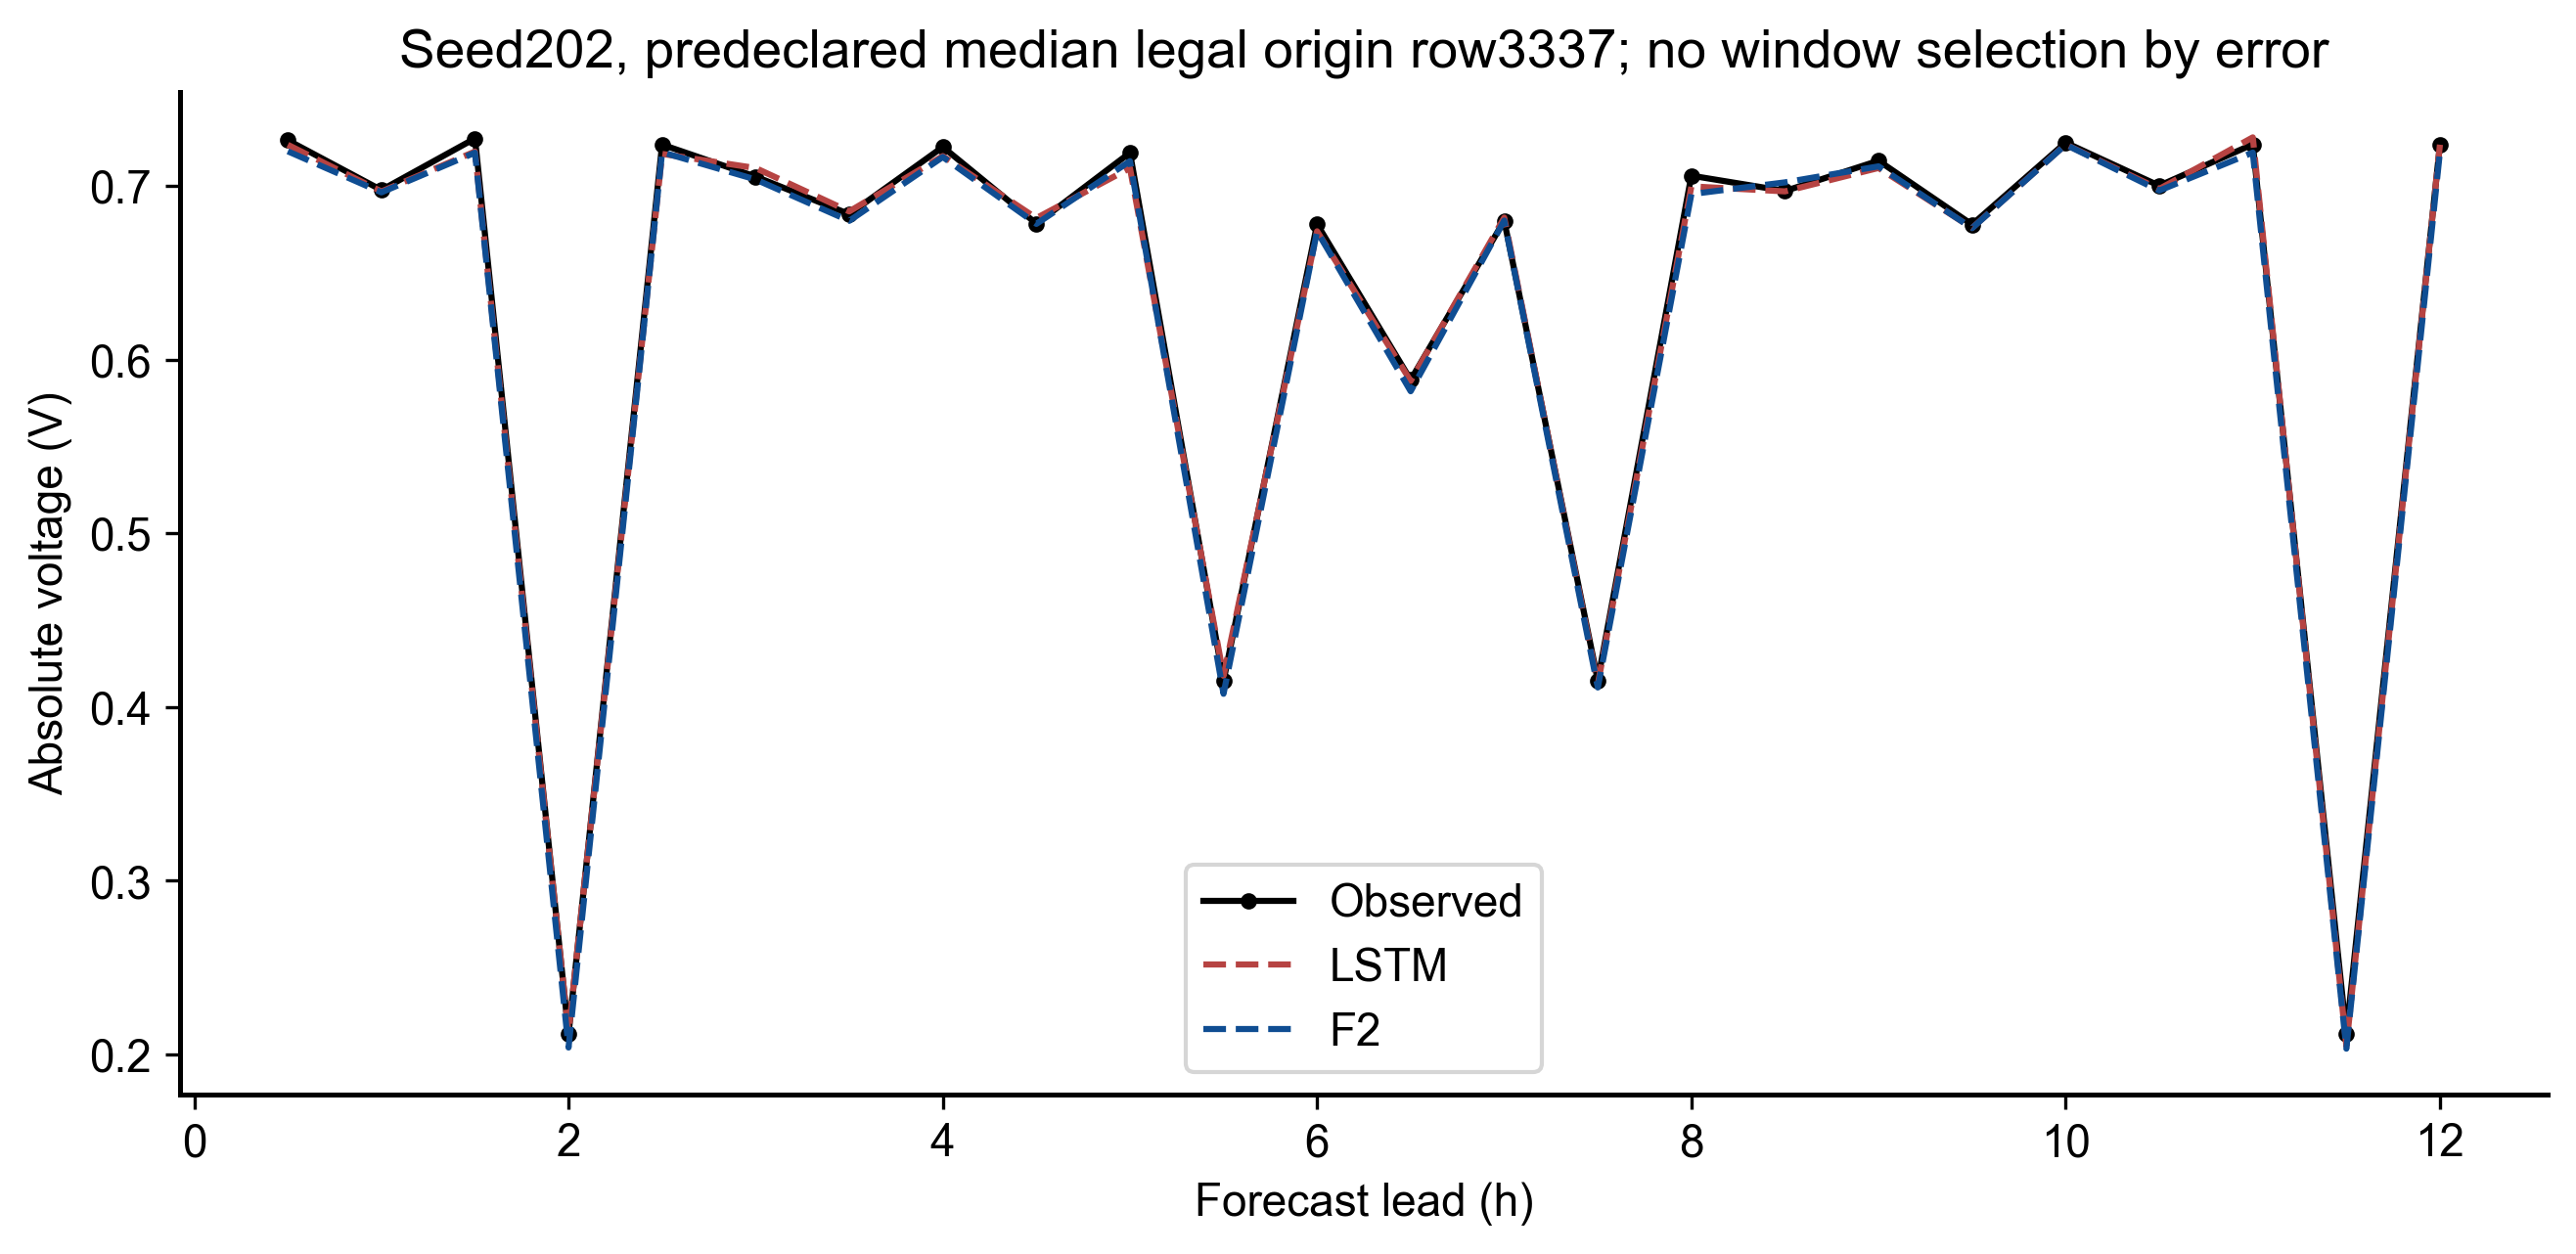

P4: two bounded hypotheses, no extra training
P5: independently verify labels, fresh updates, early stopping, metrics and checkpoints
P5 INDEPENDENT_AUDIT_PASS: 14fresh trainings,12formal models, all new checkpoint replays exact
COMPARISON_PIPELINE_COMPLETED E:\沈农信电\ PEMFC-SOH+RUL\RENew-PEMFC-2300h-Pytorch\F2_LSTM_DualPath_Comparison\outputs\20261019T090430_205588Z_Top10_LSTM_F2


In [6]:
from finish import finalize
finalize(run,frame,windows,scaler,prepared,table,means,paired)
print('COMPARISON_PIPELINE_COMPLETED',str(run),flush=True)